# **Problem Statement**

## Business Context

Renewable energy sources play an increasingly important role in the global energy mix, as the effort to reduce the environmental impact of energy production increases.

Out of all the renewable energy alternatives, wind energy is one of the most developed technologies worldwide. The U.S Department of Energy has put together a guide to achieving operational efficiency using predictive maintenance practices.

Predictive maintenance uses sensor information and analysis methods to measure and predict degradation and future component capability. The idea behind predictive maintenance is that failure patterns are predictable and if component failure can be predicted accurately and the component is replaced before it fails, the costs of operation and maintenance will be much lower.

The sensors fitted across different machines involved in the process of energy generation collect data related to various environmental factors (temperature, humidity, wind speed, etc.) and additional features related to various parts of the wind turbine (gearbox, tower, blades, break, etc.).

## Objective

“ReneWind” is a company working on improving the machinery/processes involved in the production of wind energy using machine learning and has collected data of generator failure of wind turbines using sensors. They have shared a ciphered version of the data, as the data collected through sensors is confidential (the type of data collected varies with companies). Data has 40 predictors, 20000 observations in the training set and 5000 in the test set.

The objective is to build various classification models, tune them, and find the best one that will help identify failures so that the generators could be repaired before failing/breaking to reduce the overall maintenance cost.
The nature of predictions made by the classification model will translate as follows:

- True positives (TP) are failures correctly predicted by the model. These will result in repairing costs.
- False negatives (FN) are real failures where there is no detection by the model. These will result in replacement costs.
- False positives (FP) are detections where there is no failure. These will result in inspection costs.

It is given that the cost of repairing a generator is much less than the cost of replacing it, and the cost of inspection is less than the cost of repair.

“1” in the target variables should be considered as “failure” and “0” represents “No failure”.

## Data Description

The data provided is a transformed version of the original data which was collected using sensors.

- Train.csv - To be used for training and tuning of models.
- Test.csv - To be used only for testing the performance of the final best model.

Both the datasets consist of 40 predictor variables and 1 target variable.

# **Installing and Importing the necessary libraries**

In [ ]:
# Installing the libraries with the specified version
!pip install --no-deps tensorflow==2.18.0 scikit-learn==1.3.2 matplotlib===3.8.3 seaborn==0.13.2 numpy==1.26.4 pandas==2.2.2 -q --user --no-warn-script-location

In [ ]:
# Library for data manipulation and analysis.
import pandas as pd
# Fundamental package for scientific computing.
import numpy as np
#splitting datasets into training and testing sets.
from sklearn.model_selection import train_test_split
#Imports tools for data preprocessing including label encoding, one-hot encoding, and standard scaling
from sklearn.preprocessing import LabelEncoder, OneHotEncoder,StandardScaler
#Imports a class for imputing missing values in datasets.
from sklearn.impute import SimpleImputer
#Imports the Matplotlib library for creating visualizations.
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
# Imports the Seaborn library for statistical data visualization.
import seaborn as sns
# Time related functions.
import time
#Imports functions for evaluating the performance of machine learning models
from sklearn.metrics import confusion_matrix, f1_score,accuracy_score, recall_score, precision_score, classification_report
#Imports metrics from
from sklearn import metrics

#Imports the tensorflow,keras and layers.
import tensorflow
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dense, Input, Dropout,BatchNormalization
from tensorflow.keras import backend

# to suppress unnecessary warnings
import warnings
warnings.filterwarnings("ignore")

**Note**:
- After running the above cell, kindly restart the runtime (for Google Colab) or notebook kernel (for Jupyter Notebook), and run all cells sequentially from the next cell.
- On executing the above line of code, you might see a warning regarding package dependencies. This error message can be ignored as the above code ensures that all necessary libraries and their dependencies are maintained to successfully execute the code in ***this notebook***.

# **Loading the Data**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
df = pd.read_csv("/content/drive/My Drive/AIML/Project4/Train.csv")
df_test = pd.read_csv("/content/drive/My Drive/AIML/Project4/Test.csv")

In [ ]:
data = df.copy()
data_test = df_test.copy()

# **Data Overview**

## Training data overview

###Check: Shape of data | First few rows | Data types | Statistical summary

In [ ]:
data.shape

(20000, 41)

OBSERVATIONS:
- We have 20000 rows and 41 columns (40 features for evaluation, 1 target variable)

In [ ]:
data.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V32,V33,V34,V35,V36,V37,V38,V39,V40,Target
0,-4.464606,-4.679129,3.101546,0.506130,-0.221083,-2.032511,-2.910870,0.050714,-1.522351,3.761892,...,3.059700,-1.690440,2.846296,2.235198,6.667486,0.443809,-2.369169,2.950578,-3.480324,0
1,3.365912,3.653381,0.909671,-1.367528,0.332016,2.358938,0.732600,-4.332135,0.565695,-0.101080,...,-1.795474,3.032780,-2.467514,1.894599,-2.297780,-1.731048,5.908837,-0.386345,0.616242,0
2,-3.831843,-5.824444,0.634031,-2.418815,-1.773827,1.016824,-2.098941,-3.173204,-2.081860,5.392621,...,-0.257101,0.803550,4.086219,2.292138,5.360850,0.351993,2.940021,3.839160,-4.309402,0
3,1.618098,1.888342,7.046143,-1.147285,0.083080,-1.529780,0.207309,-2.493629,0.344926,2.118578,...,-3.584425,-2.577474,1.363769,0.622714,5.550100,-1.526796,0.138853,3.101430,-1.277378,0
4,-0.111440,3.872488,-3.758361,-2.982897,3.792714,0.544960,0.205433,4.848994,-1.854920,-6.220023,...,8.265896,6.629213,-10.068689,1.222987,-3.229763,1.686909,-2.163896,-3.644622,6.510338,0


OBSERVATIONS:
- All features for evaluation are named V1 to V40 and seem to be float values

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 41 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   V1      19982 non-null  float64
 1   V2      19982 non-null  float64
 2   V3      20000 non-null  float64
 3   V4      20000 non-null  float64
 4   V5      20000 non-null  float64
 5   V6      20000 non-null  float64
 6   V7      20000 non-null  float64
 7   V8      20000 non-null  float64
 8   V9      20000 non-null  float64
 9   V10     20000 non-null  float64
 10  V11     20000 non-null  float64
 11  V12     20000 non-null  float64
 12  V13     20000 non-null  float64
 13  V14     20000 non-null  float64
 14  V15     20000 non-null  float64
 15  V16     20000 non-null  float64
 16  V17     20000 non-null  float64
 17  V18     20000 non-null  float64
 18  V19     20000 non-null  float64
 19  V20     20000 non-null  float64
 20  V21     20000 non-null  float64
 21  V22     20000 non-null  float64
 22

OBSERVATIONS:
- All features except Target are of the type float. The Target variable can also be converted to float later even if it takes 0/1 values

In [ ]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
V1,19982.0,-0.271996,3.441625,-11.876451,-2.737146,-0.747917,1.840112,15.493002
V2,19982.0,0.440430,3.150784,-12.319951,-1.640674,0.471536,2.543967,13.089269
V3,20000.0,2.484699,3.388963,-10.708139,0.206860,2.255786,4.566165,17.090919
V4,20000.0,-0.083152,3.431595,-15.082052,-2.347660,-0.135241,2.130615,13.236381
V5,20000.0,-0.053752,2.104801,-8.603361,-1.535607,-0.101952,1.340480,8.133797
V6,20000.0,-0.995443,2.040970,-10.227147,-2.347238,-1.000515,0.380330,6.975847
V7,20000.0,-0.879325,1.761626,-7.949681,-2.030926,-0.917179,0.223695,8.006091
V8,20000.0,-0.548195,3.295756,-15.657561,-2.642665,-0.389085,1.722965,11.679495
V9,20000.0,-0.016808,2.160568,-8.596313,-1.494973,-0.067597,1.409203,8.137580
V10,20000.0,-0.012998,2.193201,-9.853957,-1.411212,0.100973,1.477045,8.108472


OBSERVATIONS:
- V1 and V2 might have missing values
- Target variable has more 0s than 1s. Hence there is class imbalance.

###Convert: target variable to float

In [ ]:
data['Target'] = data['Target'].astype(float)

### Check: Duplicate values | Missing values

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.isnull().sum()

,0
V1,18
V2,18
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0
V10,0


OBSERVATIONS:
- There are no duplicate values
- There are a few missing values in V1 and V2

## Testing data overview

###Check: Shape of data | First few rows | Data types | Statistical summary

In [ ]:
data_test.shape

(5000, 41)

OBSERVATIONS:
- Test data has 5000 rows and 41 columns

In [ ]:
data_test.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V32,V33,V34,V35,V36,V37,V38,V39,V40,Target
0,-0.613489,-3.819640,2.202302,1.300420,-1.184929,-4.495964,-1.835817,4.722989,1.206140,-0.341909,...,2.291204,-5.411388,0.870073,0.574479,4.157191,1.428093,-10.511342,0.454664,-1.448363,0
1,0.389608,-0.512341,0.527053,-2.576776,-1.016766,2.235112,-0.441301,-4.405744,-0.332869,1.966794,...,-2.474936,2.493582,0.315165,2.059288,0.683859,-0.485452,5.128350,1.720744,-1.488235,0
2,-0.874861,-0.640632,4.084202,-1.590454,0.525855,-1.957592,-0.695367,1.347309,-1.732348,0.466500,...,-1.318888,-2.997464,0.459664,0.619774,5.631504,1.323512,-1.752154,1.808302,1.675748,0
3,0.238384,1.458607,4.014528,2.534478,1.196987,-3.117330,-0.924035,0.269493,1.322436,0.702345,...,3.517918,-3.074085,-0.284220,0.954576,3.029331,-1.367198,-3.412140,0.906000,-2.450889,0
4,5.828225,2.768260,-1.234530,2.809264,-1.641648,-1.406698,0.568643,0.965043,1.918379,-2.774855,...,1.773841,-1.501573,-2.226702,4.776830,-6.559698,-0.805551,-0.276007,-3.858207,-0.537694,0


OBSERVATIONS:
- Data looks similar to Training data

In [ ]:
data_test.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 41 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   V1      4995 non-null   float64
 1   V2      4994 non-null   float64
 2   V3      5000 non-null   float64
 3   V4      5000 non-null   float64
 4   V5      5000 non-null   float64
 5   V6      5000 non-null   float64
 6   V7      5000 non-null   float64
 7   V8      5000 non-null   float64
 8   V9      5000 non-null   float64
 9   V10     5000 non-null   float64
 10  V11     5000 non-null   float64
 11  V12     5000 non-null   float64
 12  V13     5000 non-null   float64
 13  V14     5000 non-null   float64
 14  V15     5000 non-null   float64
 15  V16     5000 non-null   float64
 16  V17     5000 non-null   float64
 17  V18     5000 non-null   float64
 18  V19     5000 non-null   float64
 19  V20     5000 non-null   float64
 20  V21     5000 non-null   float64
 21  V22     5000 non-null   float64
 22  

In [ ]:
data_test.describe().T

,count,mean,std,min,25%,50%,75%,max
V1,4995.0,-0.277622,3.466280,-12.381696,-2.743691,-0.764767,1.831313,13.504352
V2,4994.0,0.397928,3.139562,-10.716179,-1.649211,0.427369,2.444486,14.079073
V3,5000.0,2.551787,3.326607,-9.237940,0.314931,2.260428,4.587000,15.314503
V4,5000.0,-0.048943,3.413937,-14.682446,-2.292694,-0.145753,2.166468,12.140157
V5,5000.0,-0.080120,2.110870,-7.711569,-1.615238,-0.131890,1.341197,7.672835
V6,5000.0,-1.042138,2.005444,-8.924196,-2.368853,-1.048571,0.307555,5.067685
V7,5000.0,-0.907922,1.769017,-8.124230,-2.054259,-0.939695,0.212228,7.616182
V8,5000.0,-0.574592,3.331911,-12.252731,-2.642088,-0.357943,1.712896,10.414722
V9,5000.0,0.030121,2.174139,-6.785495,-1.455712,-0.079891,1.449548,8.850720
V10,5000.0,0.018524,2.145437,-8.170956,-1.353320,0.166292,1.511248,6.598728


OBSERVATIONS:
- Similar to that of training data
- Here too, V1, V2 might have missing values.
- The target variable is of type int. We can convert that to float for our model uniformity.


###Convert: target variable to float

In [ ]:
data_test['Target'] = data_test['Target'].astype(float)

### Check: Duplicate values | Missing values

In [ ]:
df_test.duplicated().sum()

np.int64(0)

In [ ]:
df_test.isnull().sum()

,0
V1,5
V2,6
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0
V10,0


OBSERVATIONS:
- There are no duplicate values
- There are a few missing values in V1 and V2

# **Exploratory Data Analysis**

In [ ]:
feature_cols = data.columns.tolist()
feature_cols.remove('Target')

## Univariate analysis

In [ ]:
# function to plot a boxplot and a histogram along the same scale.


def histogram_boxplot(data, feature, figsize=(12, 7), kde=False, bins=None):
    """
    Boxplot and histogram combined

    data: dataframe
    feature: dataframe column
    figsize: size of figure (default (12,7))
    kde: whether to the show density curve (default False)
    bins: number of bins for histogram (default None)
    """
    f2, (ax_box2, ax_hist2) = plt.subplots(
        nrows=2,  # Number of rows of the subplot grid= 2
        sharex=True,  # x-axis will be shared among all subplots
        gridspec_kw={"height_ratios": (0.25, 0.75)},
        figsize=figsize,
    )  # creating the 2 subplots
    sns.boxplot(
        data= data, x= feature, ax= ax_box2, showmeans=True, color="violet"
    )  # boxplot will be created and a star will indicate the mean value of the column
    sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2, bins=bins, palette="winter"
    ) if bins else sns.histplot(
        data=data, x=feature, kde=kde, ax=ax_hist2
    )  # For histogram
    ax_hist2.axvline(
        data[feature].mean(), color="green", linestyle="--"
    )  # Add mean to the histogram
    ax_hist2.axvline(
        data[feature].median(), color="black", linestyle="-"
    )  # Add median to the histogram

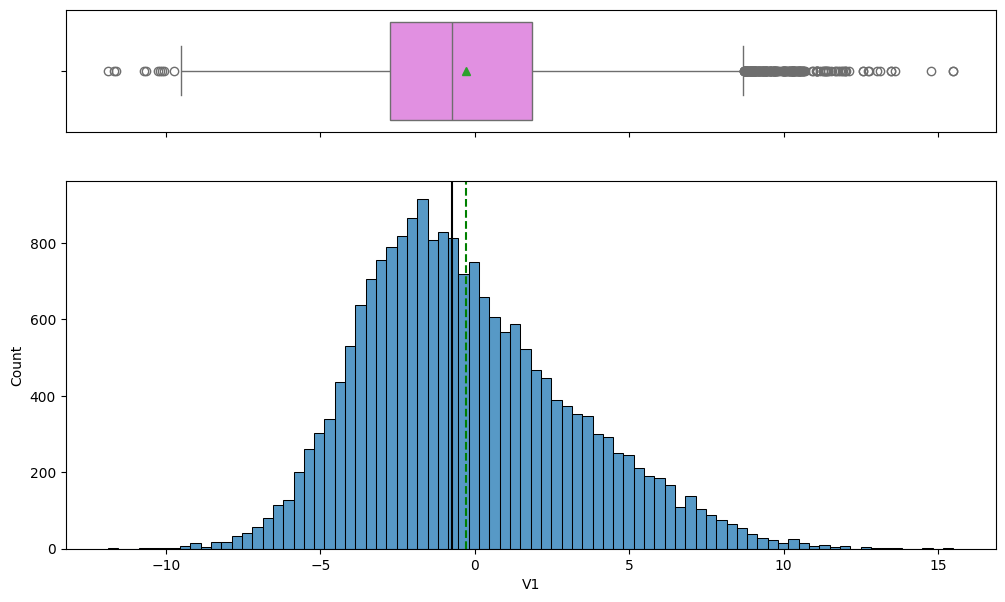

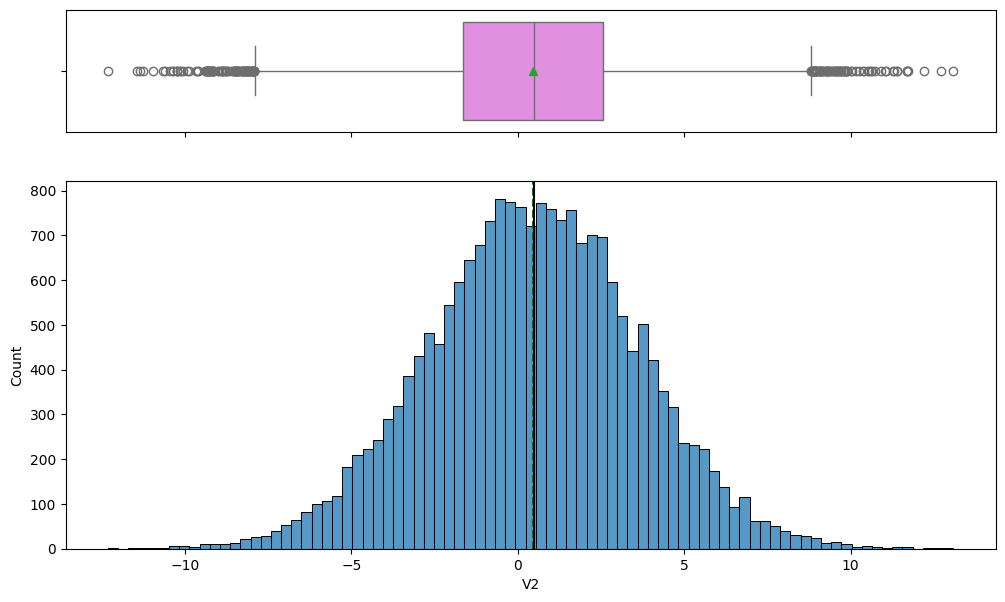

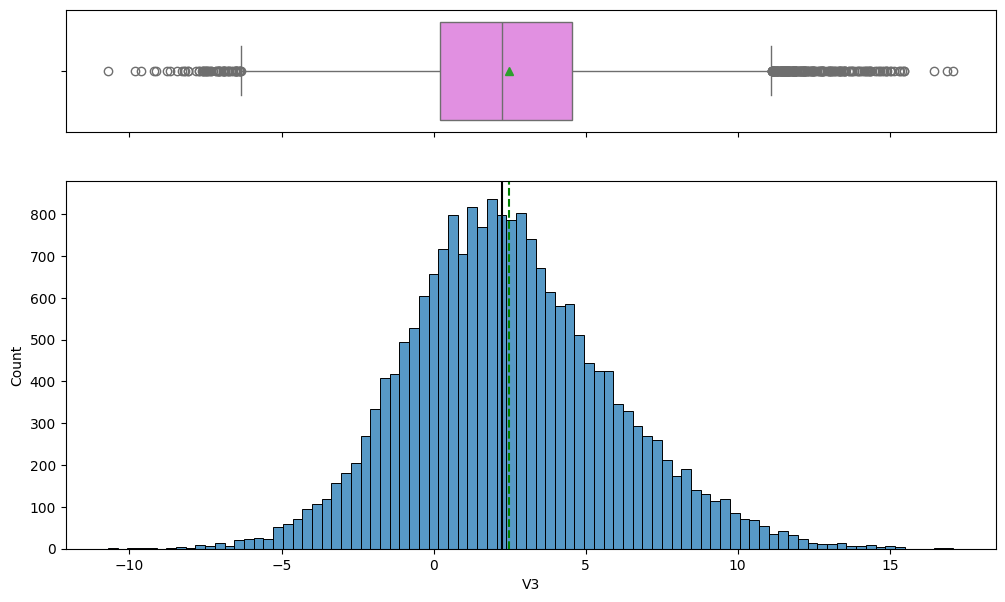

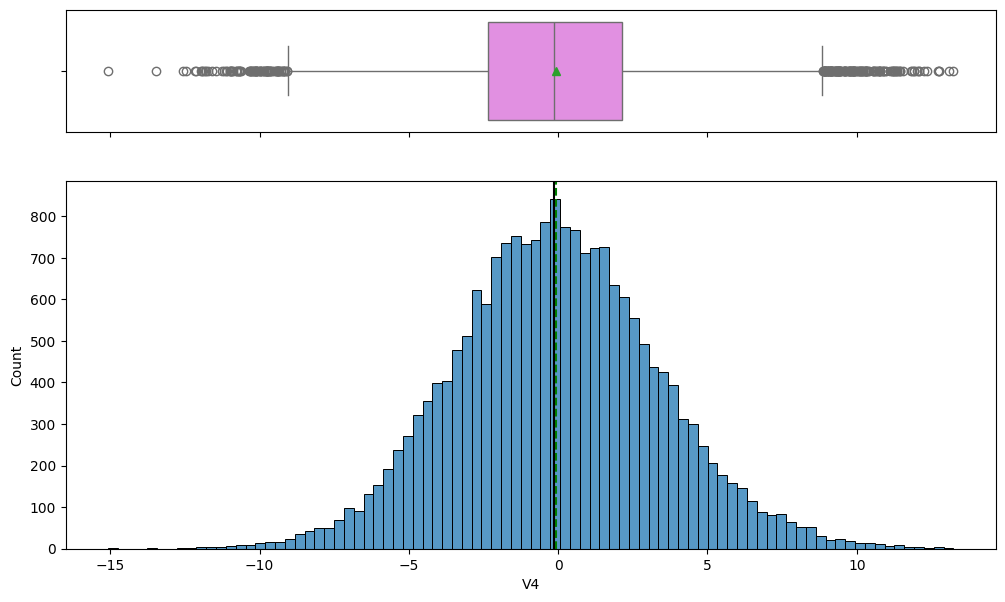

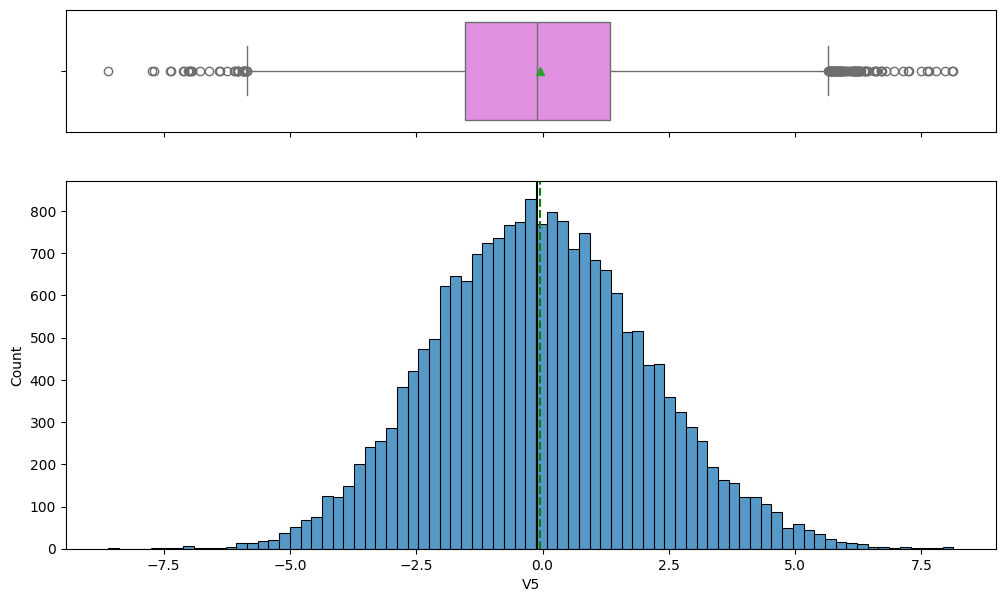

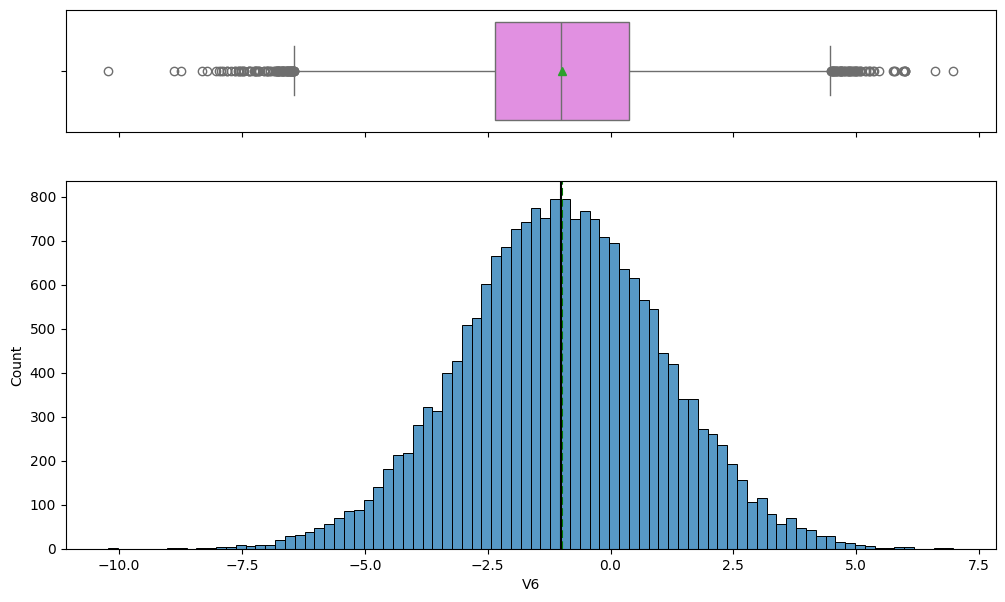

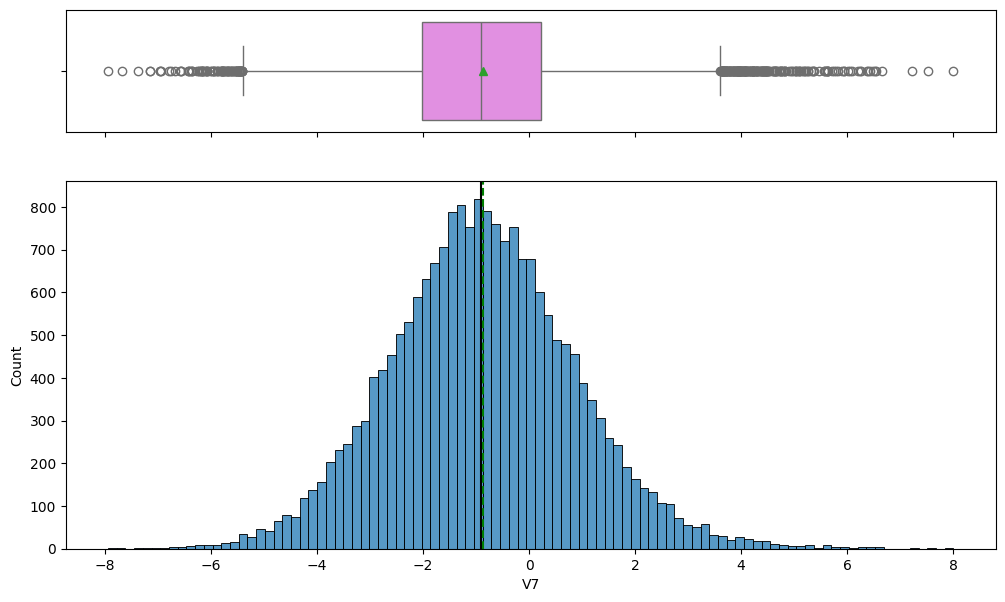

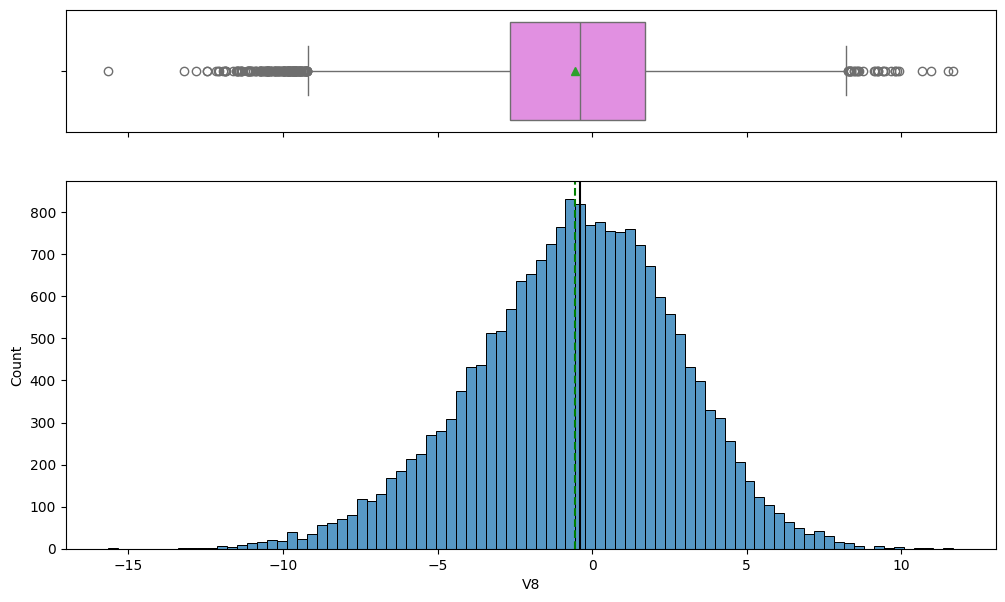

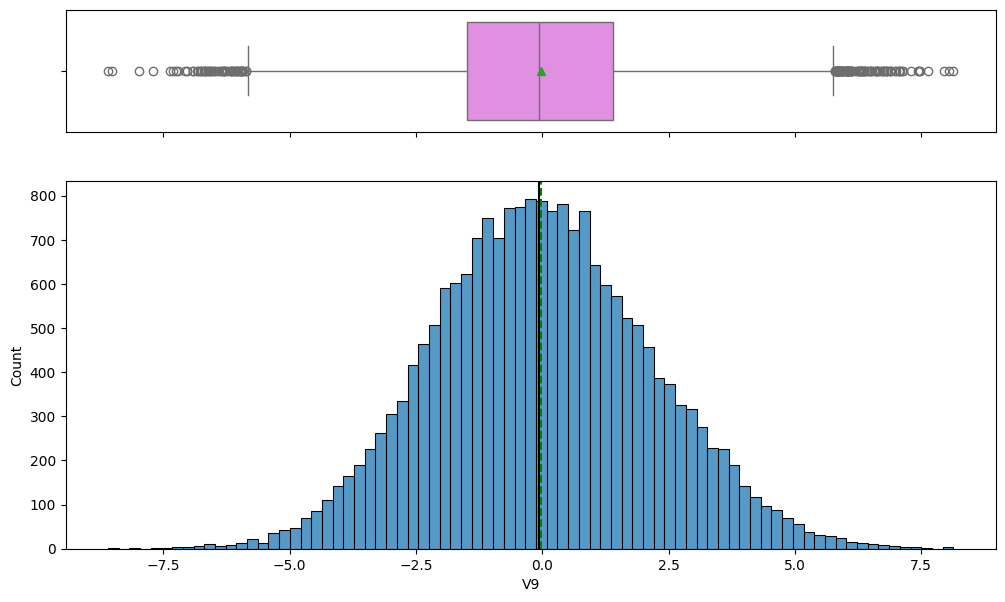

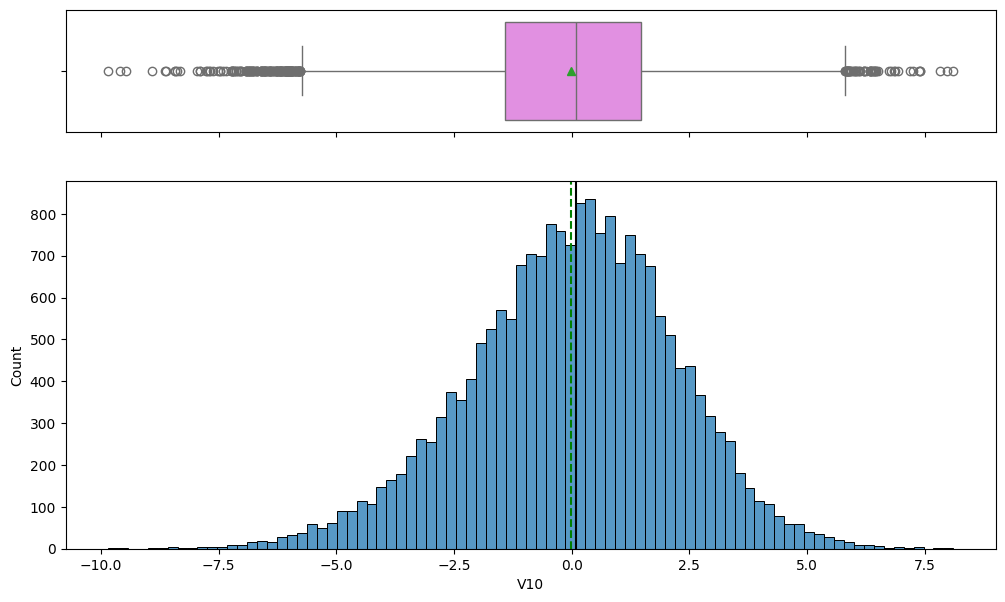

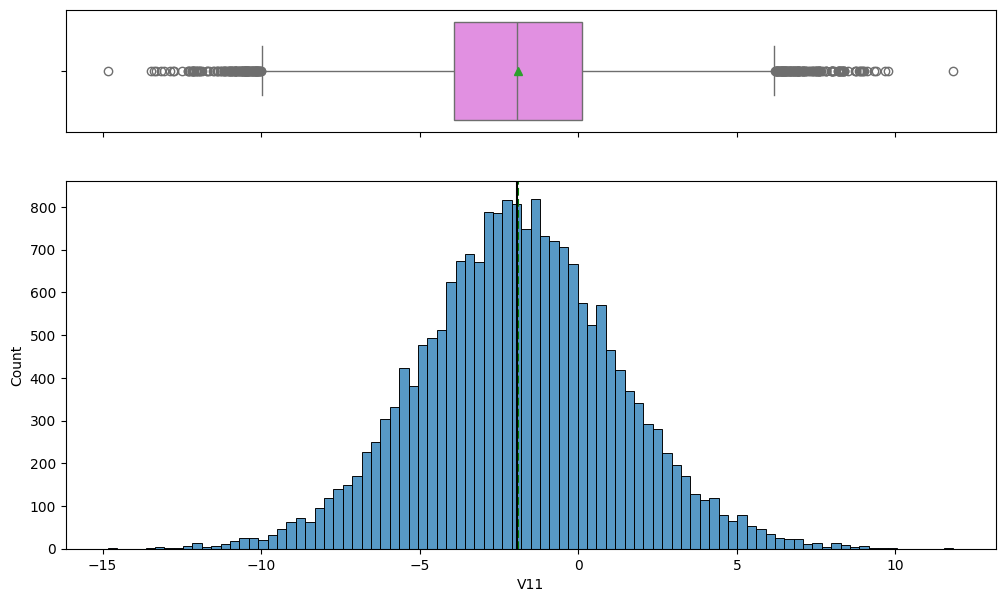

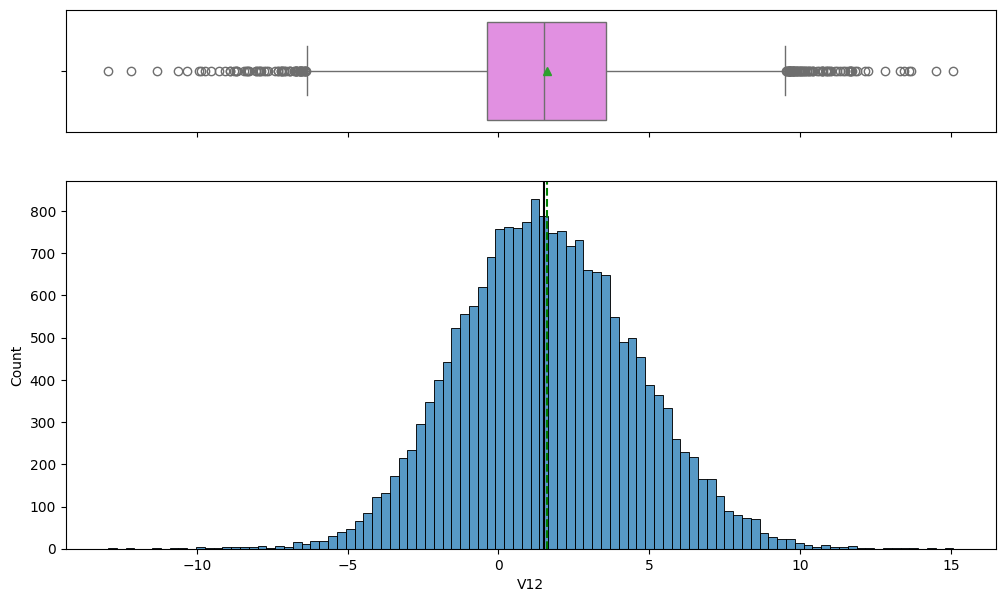

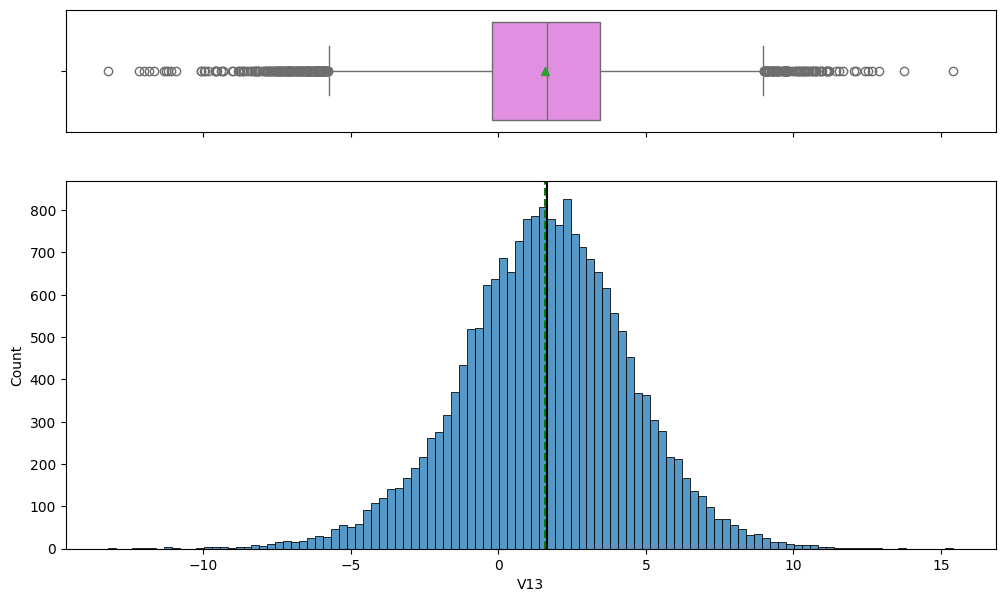

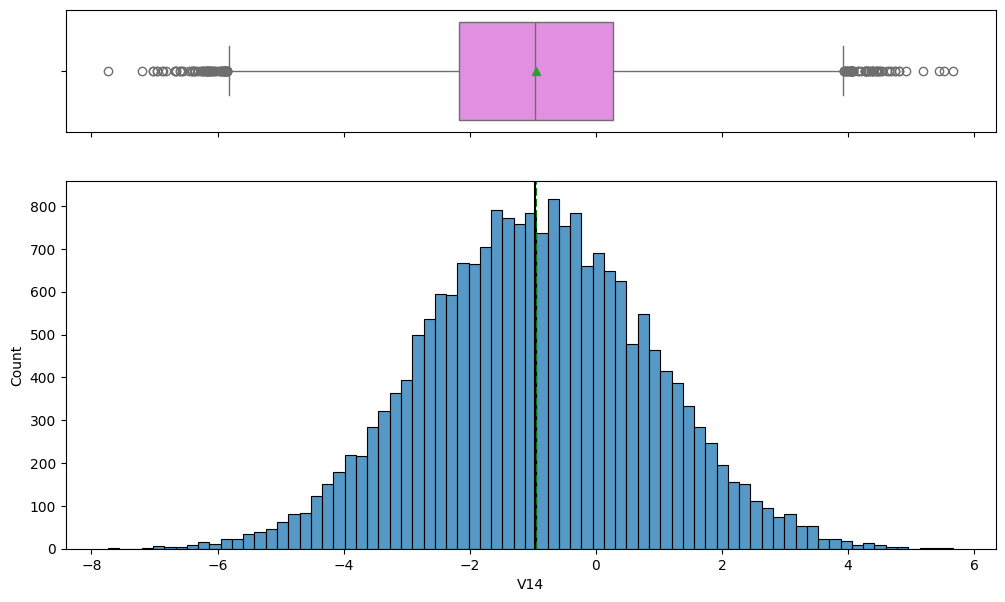

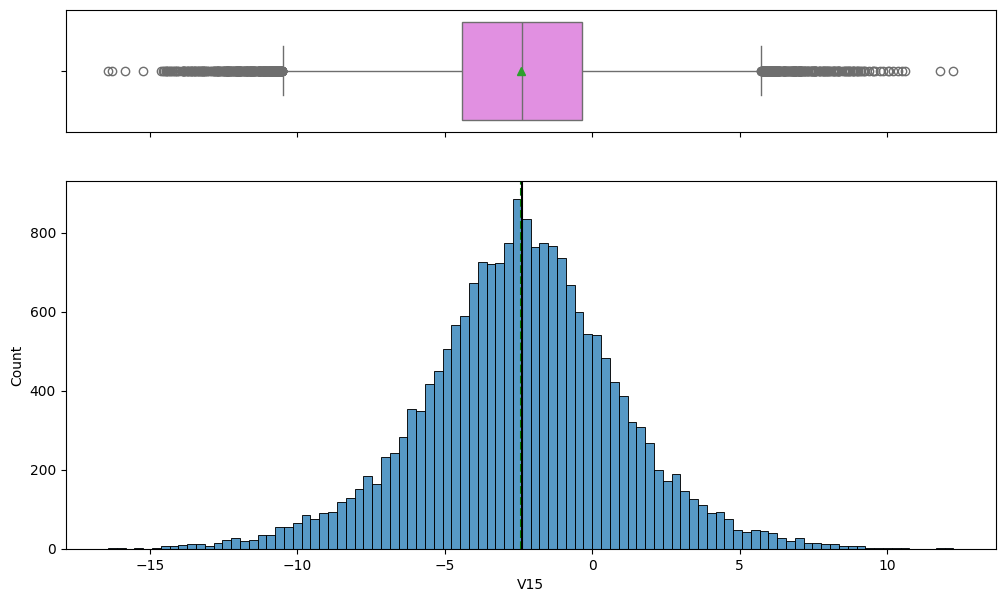

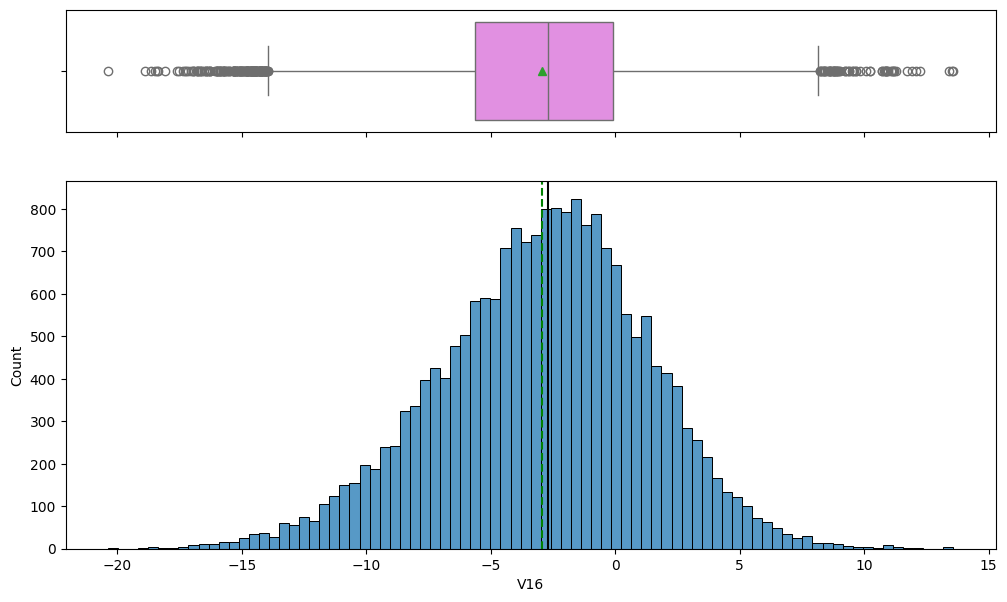

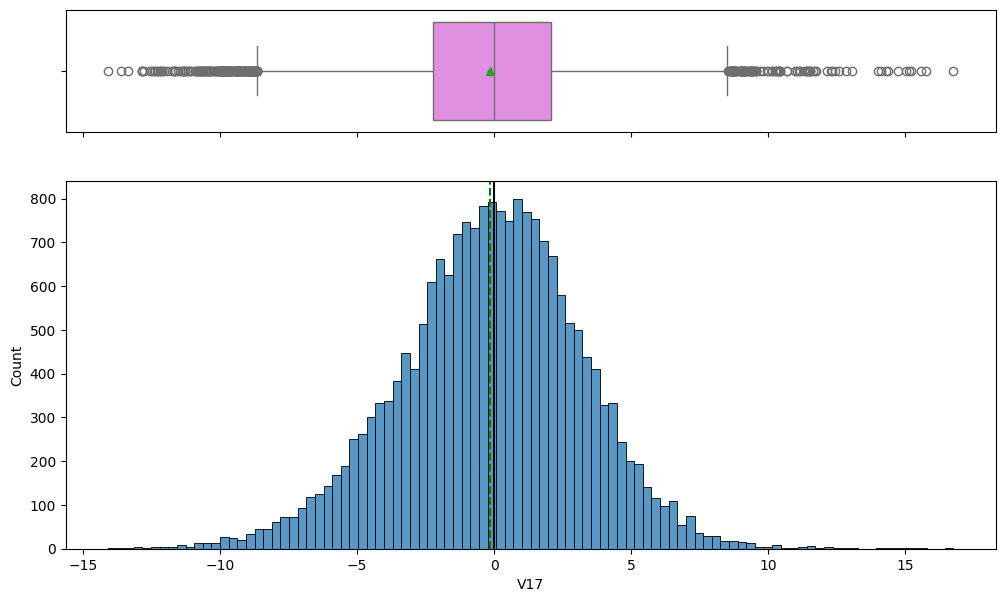

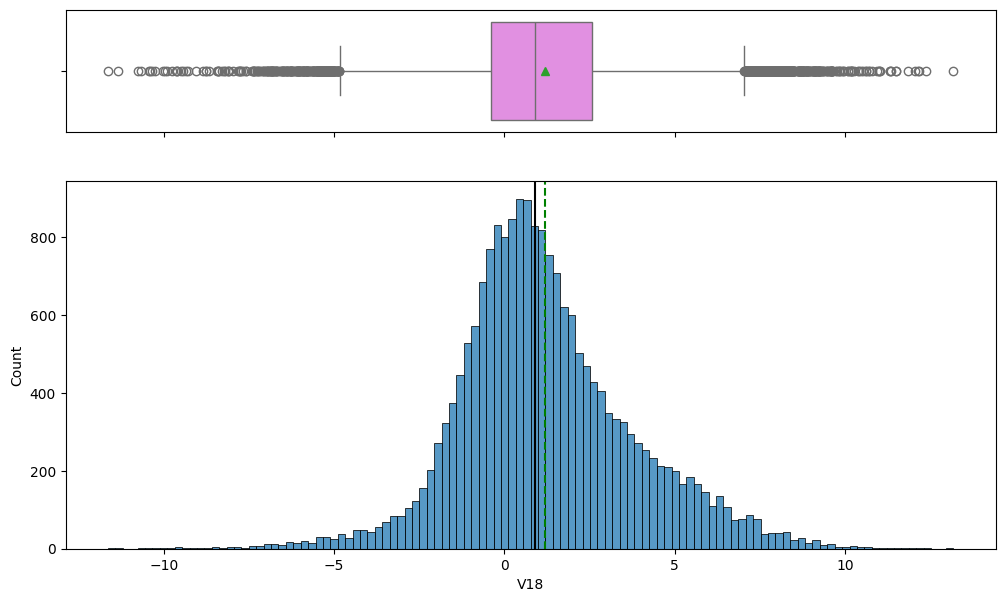

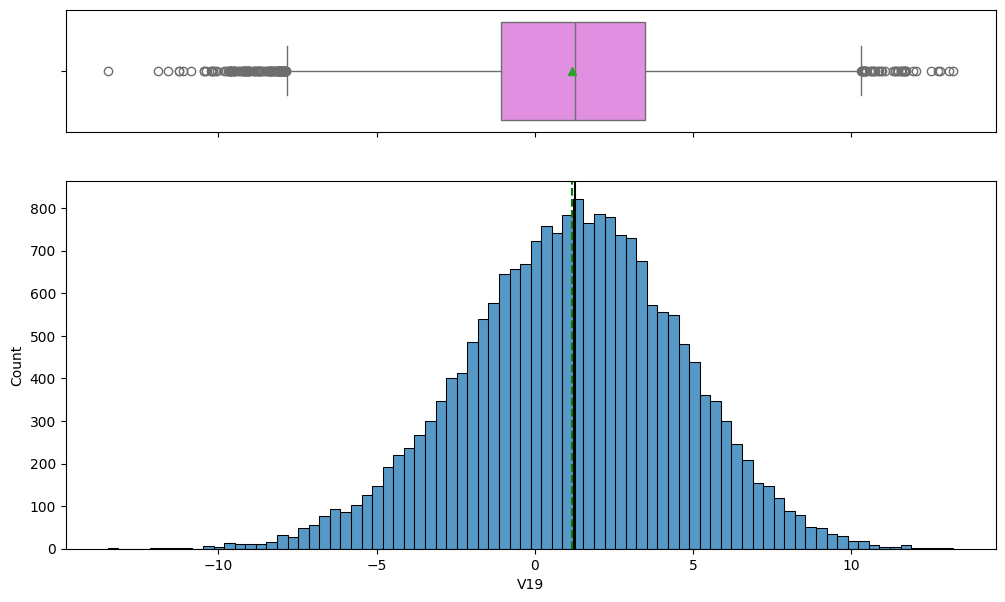

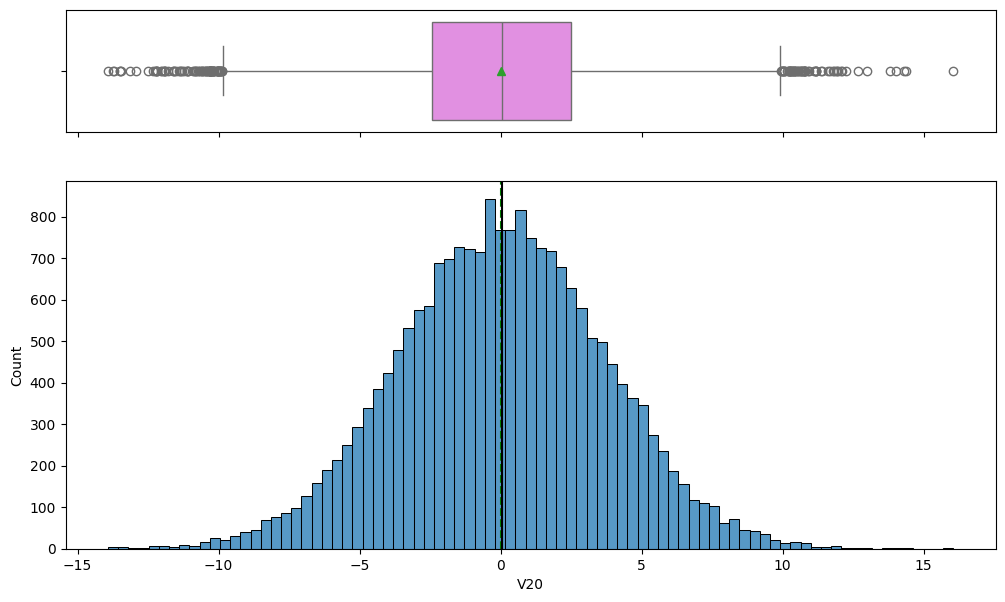

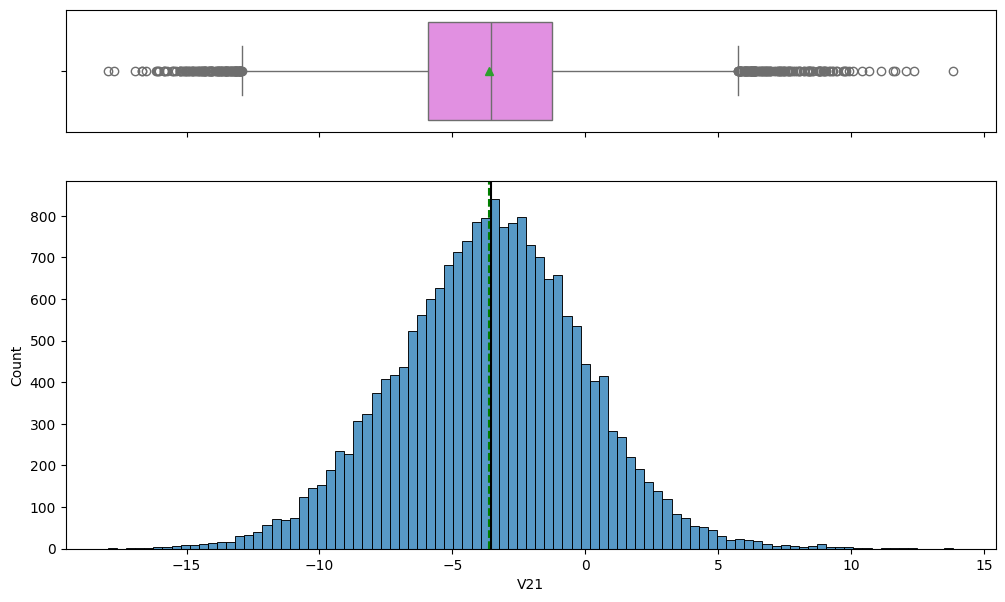

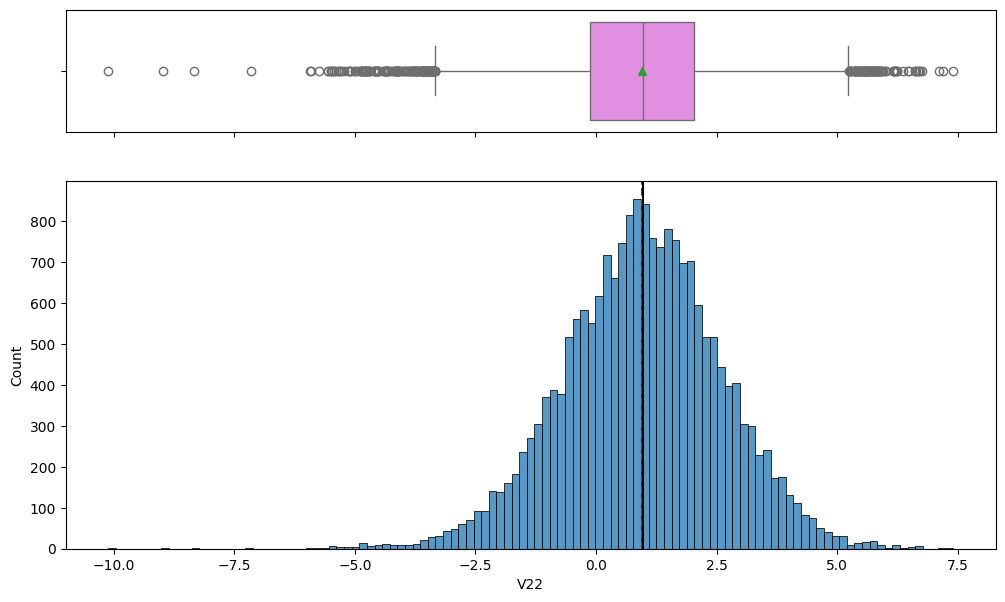

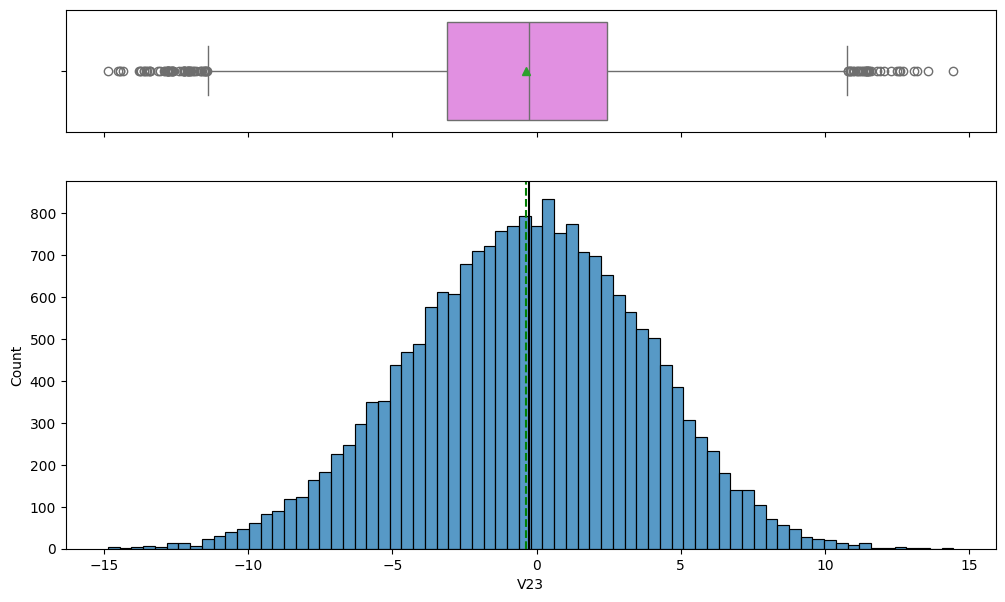

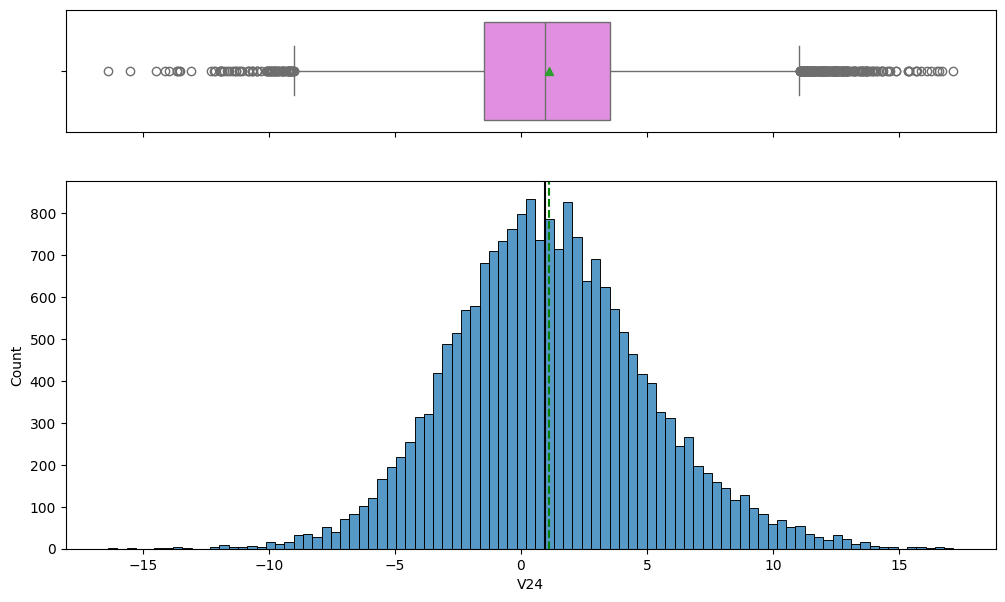

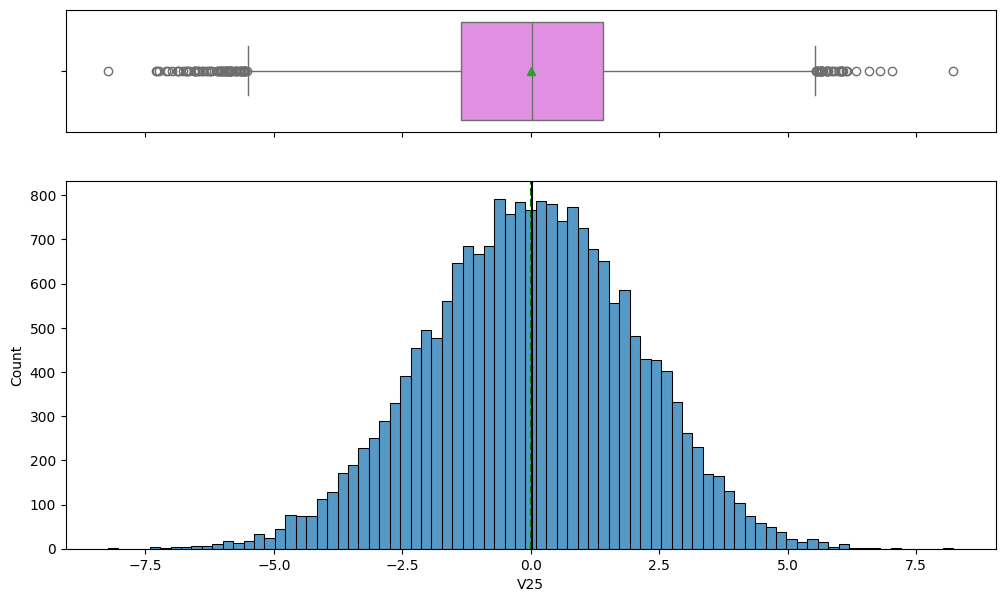

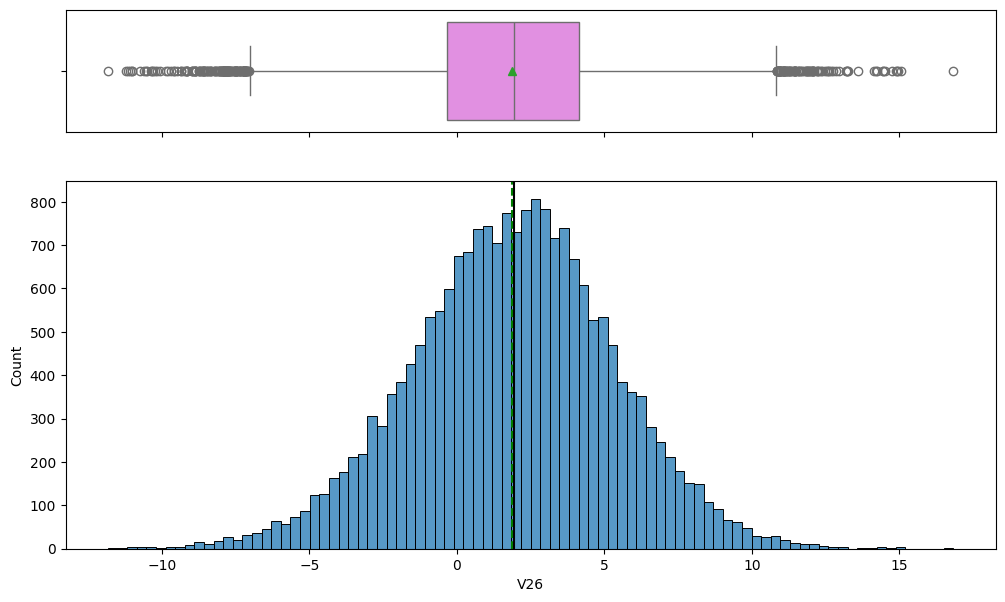

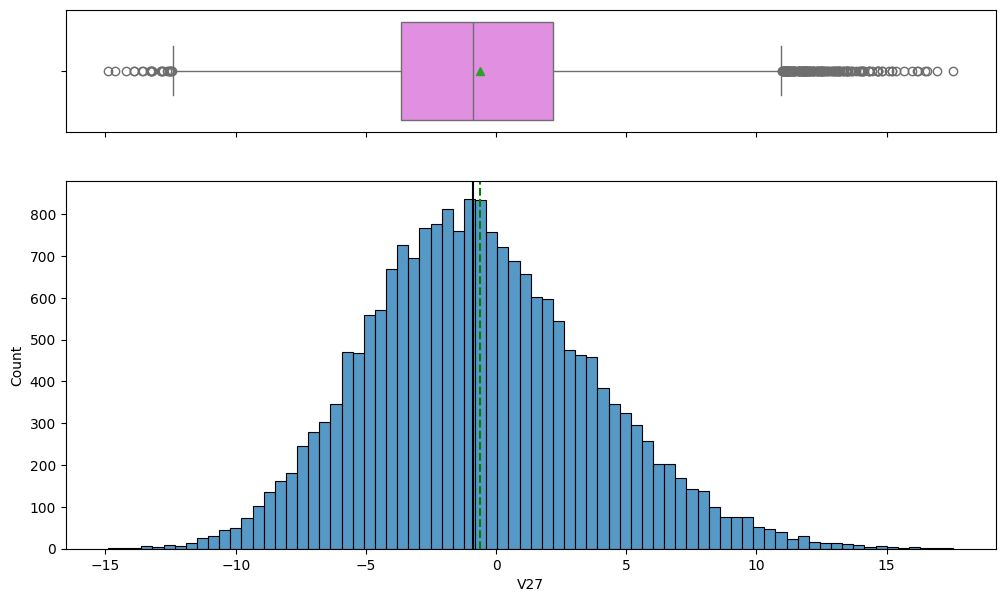

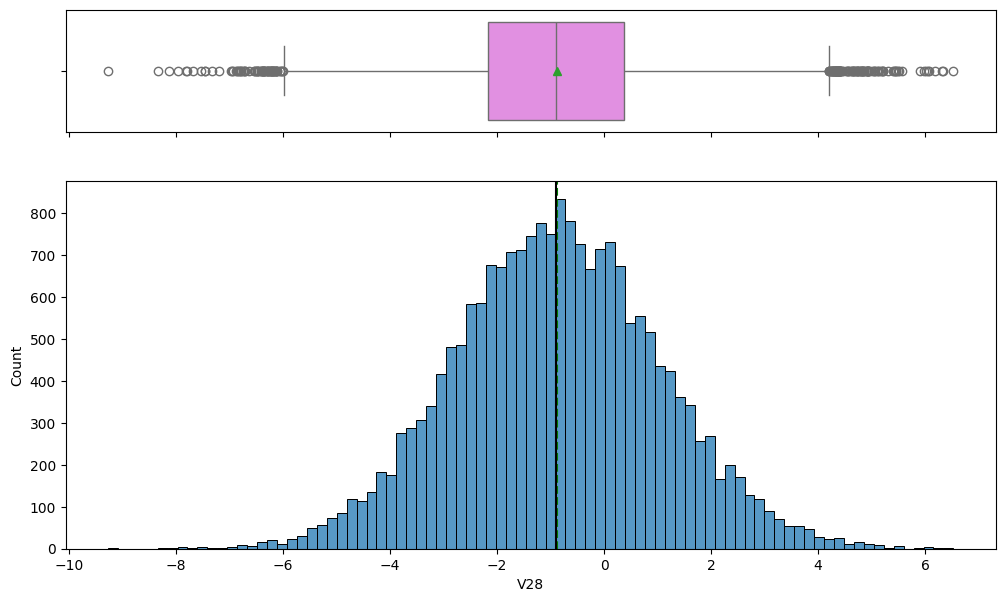

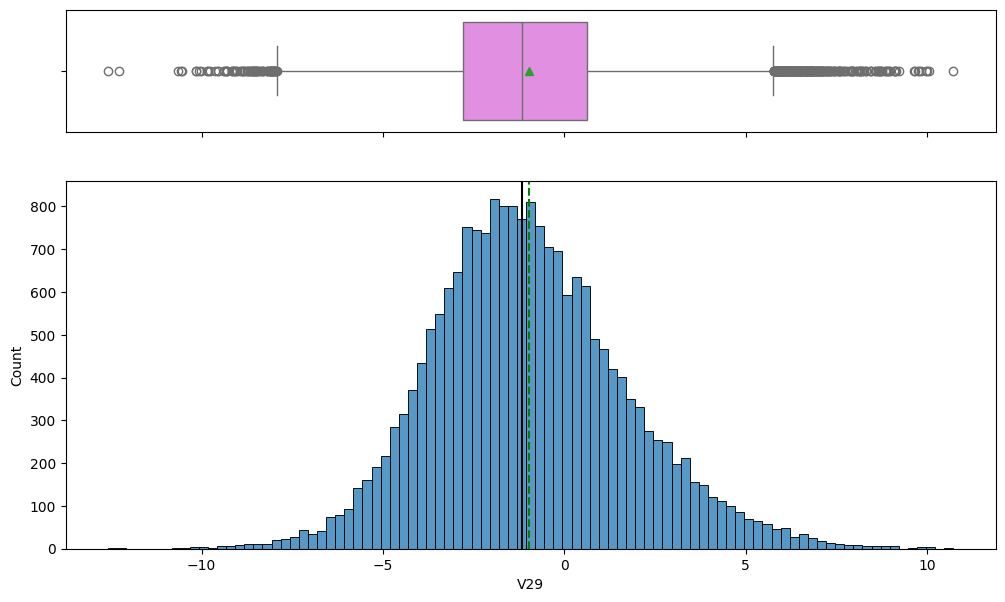

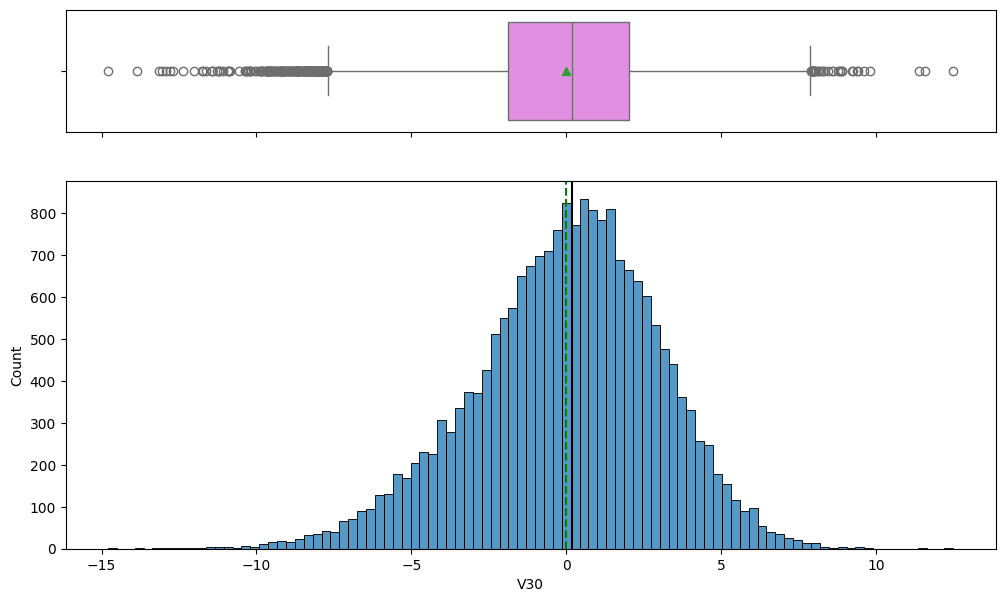

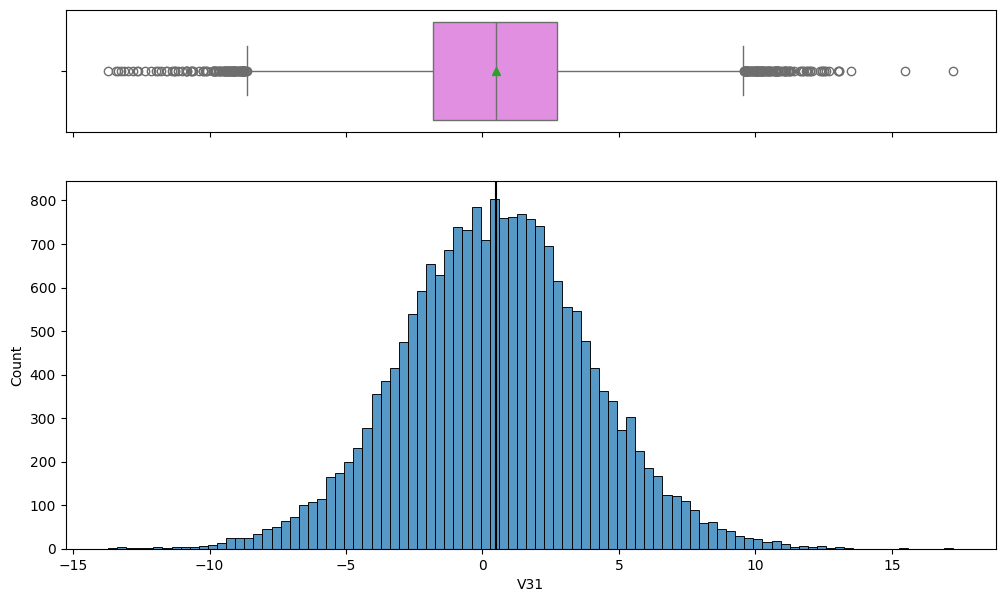

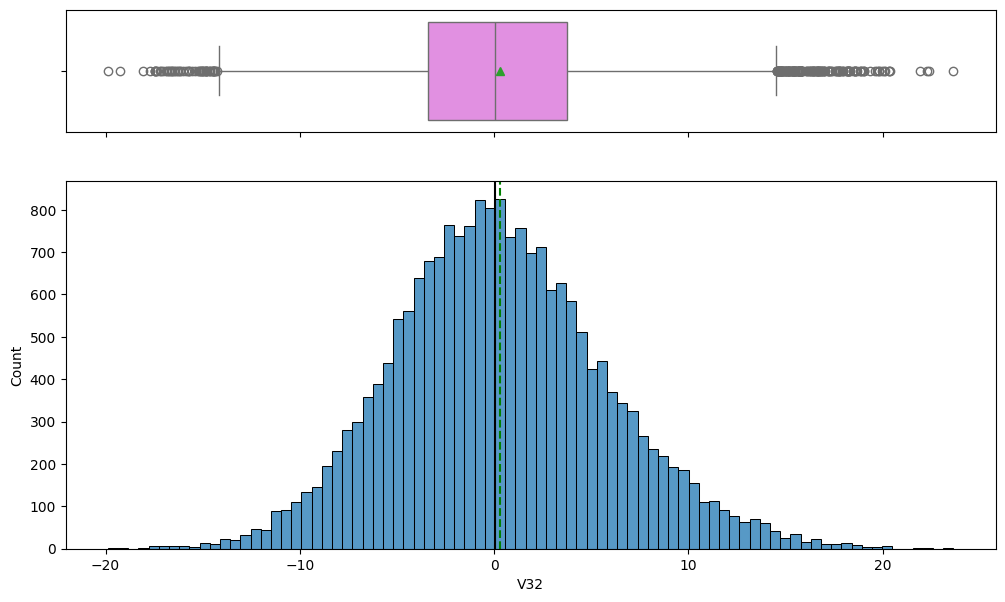

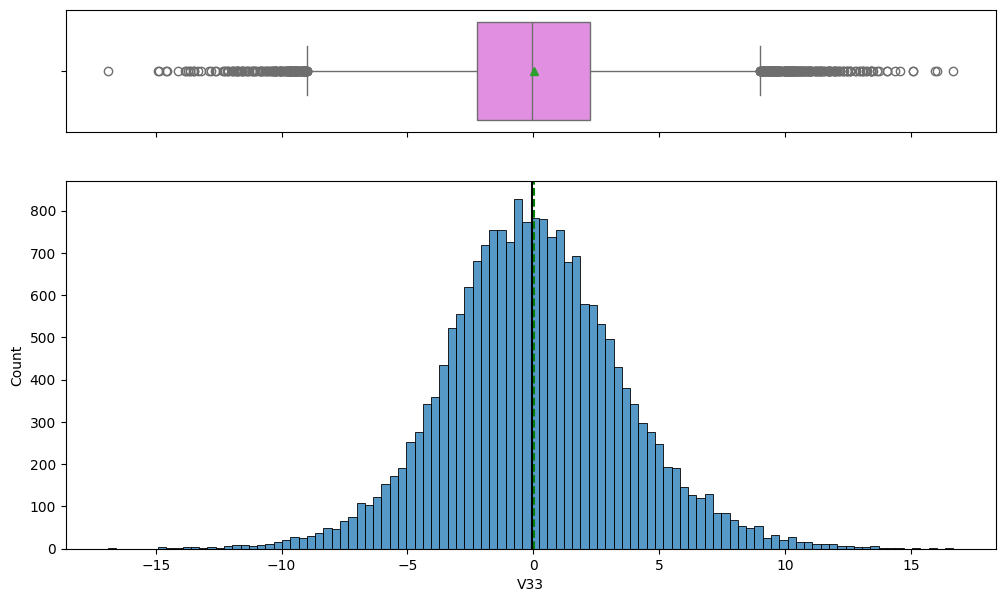

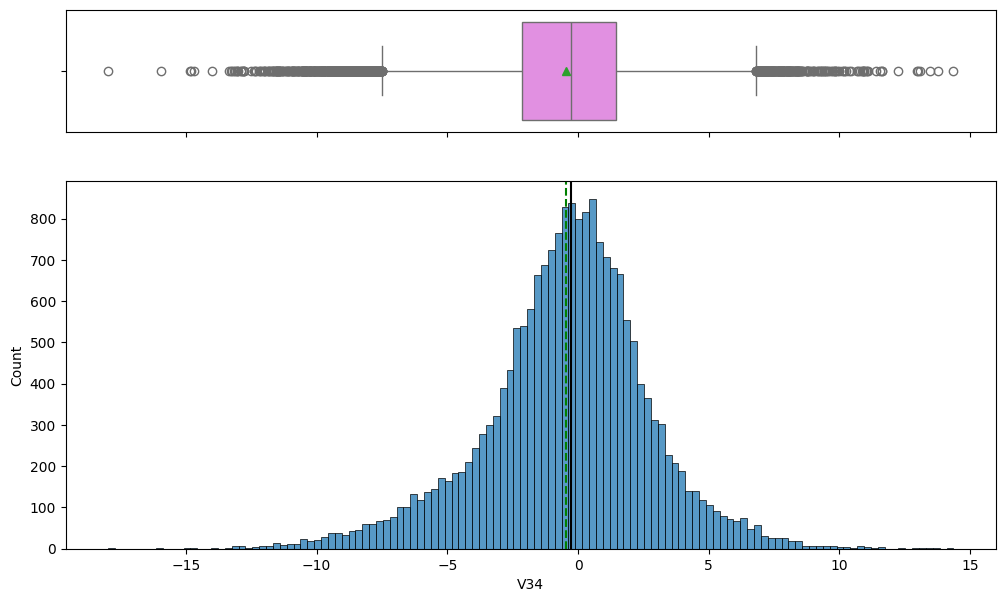

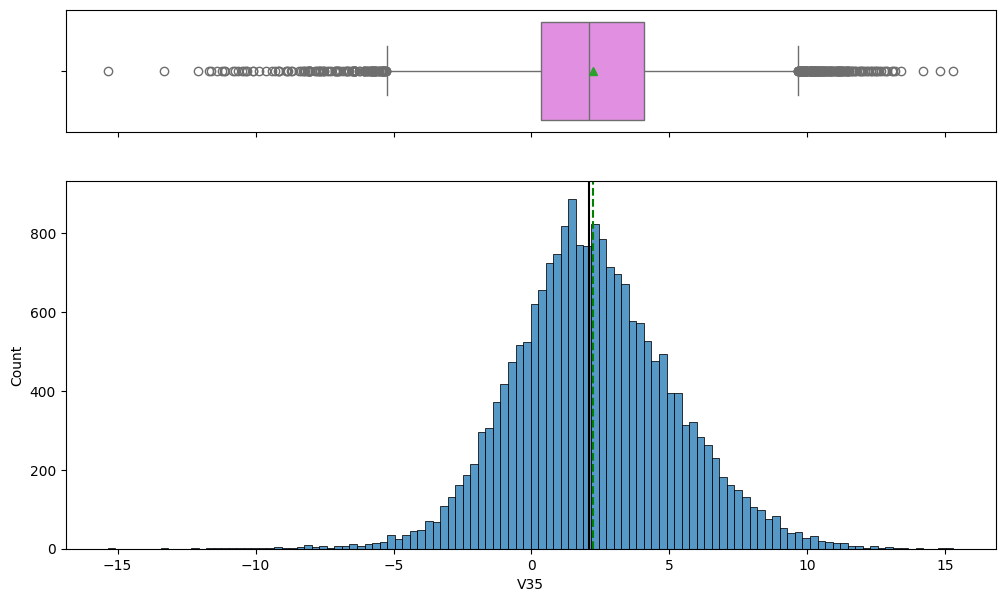

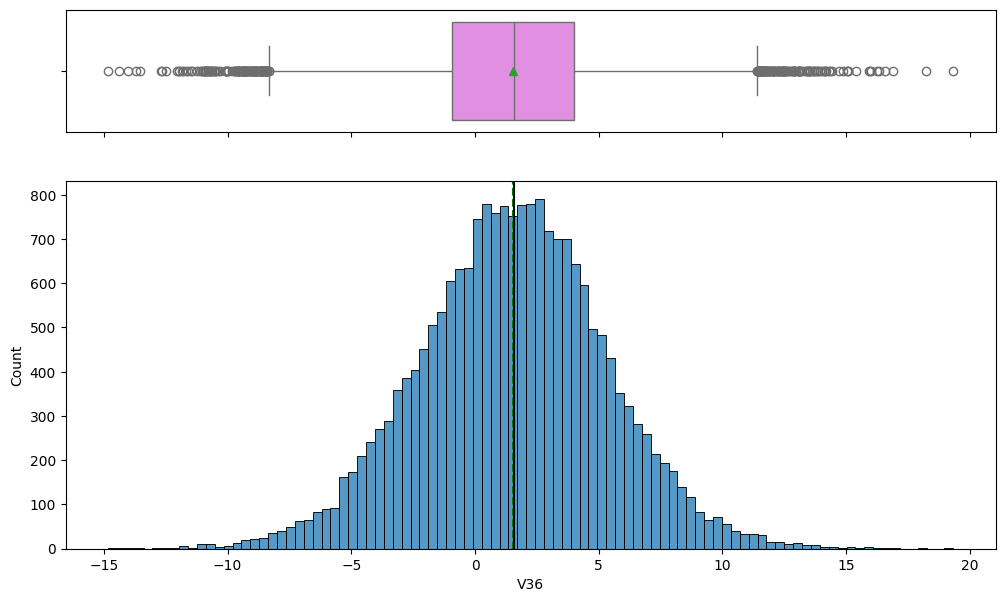

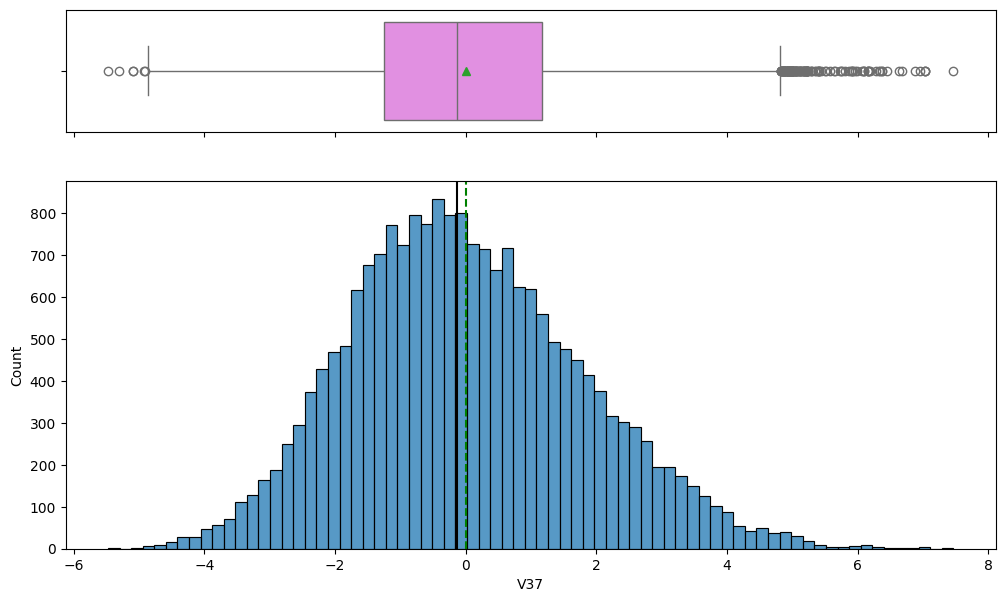

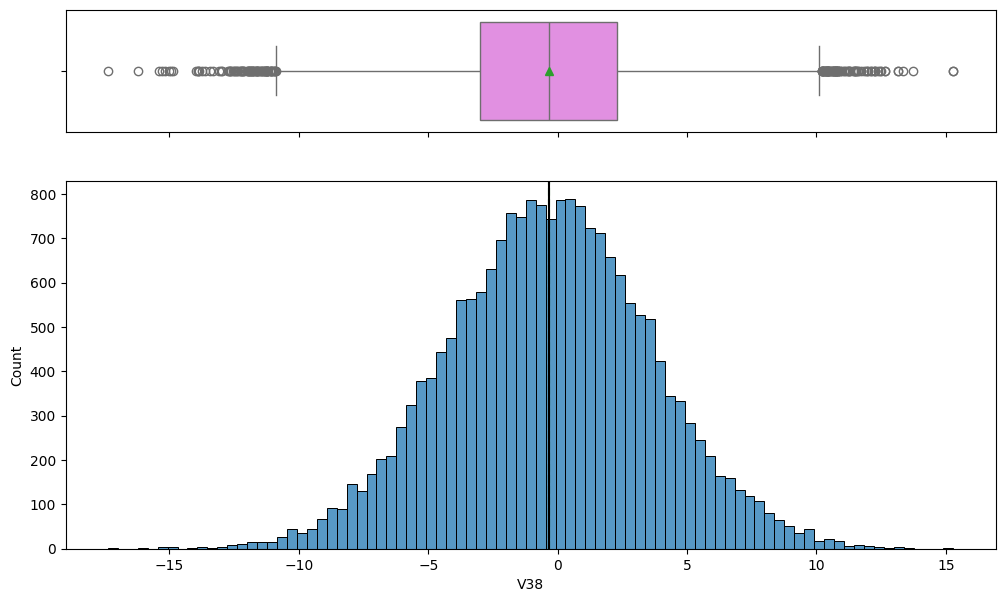

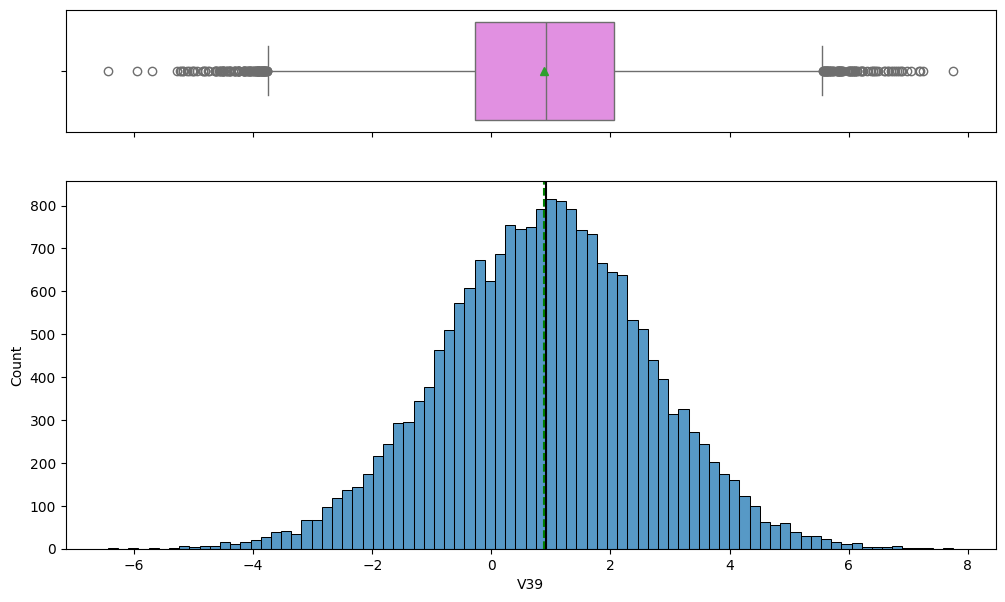

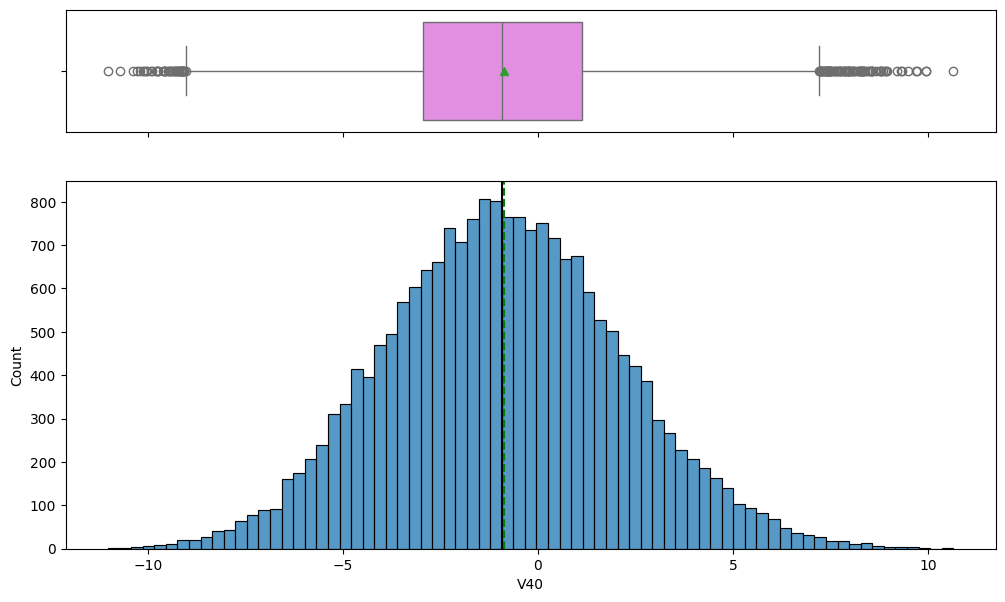

In [ ]:
for col in feature_cols:
    histogram_boxplot(data, col)

OBSERVATIONS:
- Based on the hisplots and boxplots of all 40 float variables, we can see that most of the data is evenly distributed.
- Some variables aer in similar ranges, but not all.
- All box plots have outliers.
- There is nothing much we can deduce regarding the feature importance from the graph or any particular data cleanup required.

### Check: distribution of Target variable


In [ ]:
# For train data
data["Target"].value_counts(1)

,proportion
Target,
0.0,0.9445
1.0,0.0555


OBSERVATIONS:
- The distribution of target variable is ~94.45% for no failure and 5.55% for failure in the training set
- This class imbalance will be handled later to prevent bias towards class 0 (no failures). Plus we want to predict for class 1 (failures)

In [ ]:
# For test data
data_test["Target"].value_counts(1)

,proportion
Target,
0.0,0.9436
1.0,0.0564


OBSERVATIONS:

- The distribution of target variable is ~94.36% for no failure and 5.64% for failure in the testing set which is very close distribution to the training set

## Bivariate Analysis

### Check: Correlation

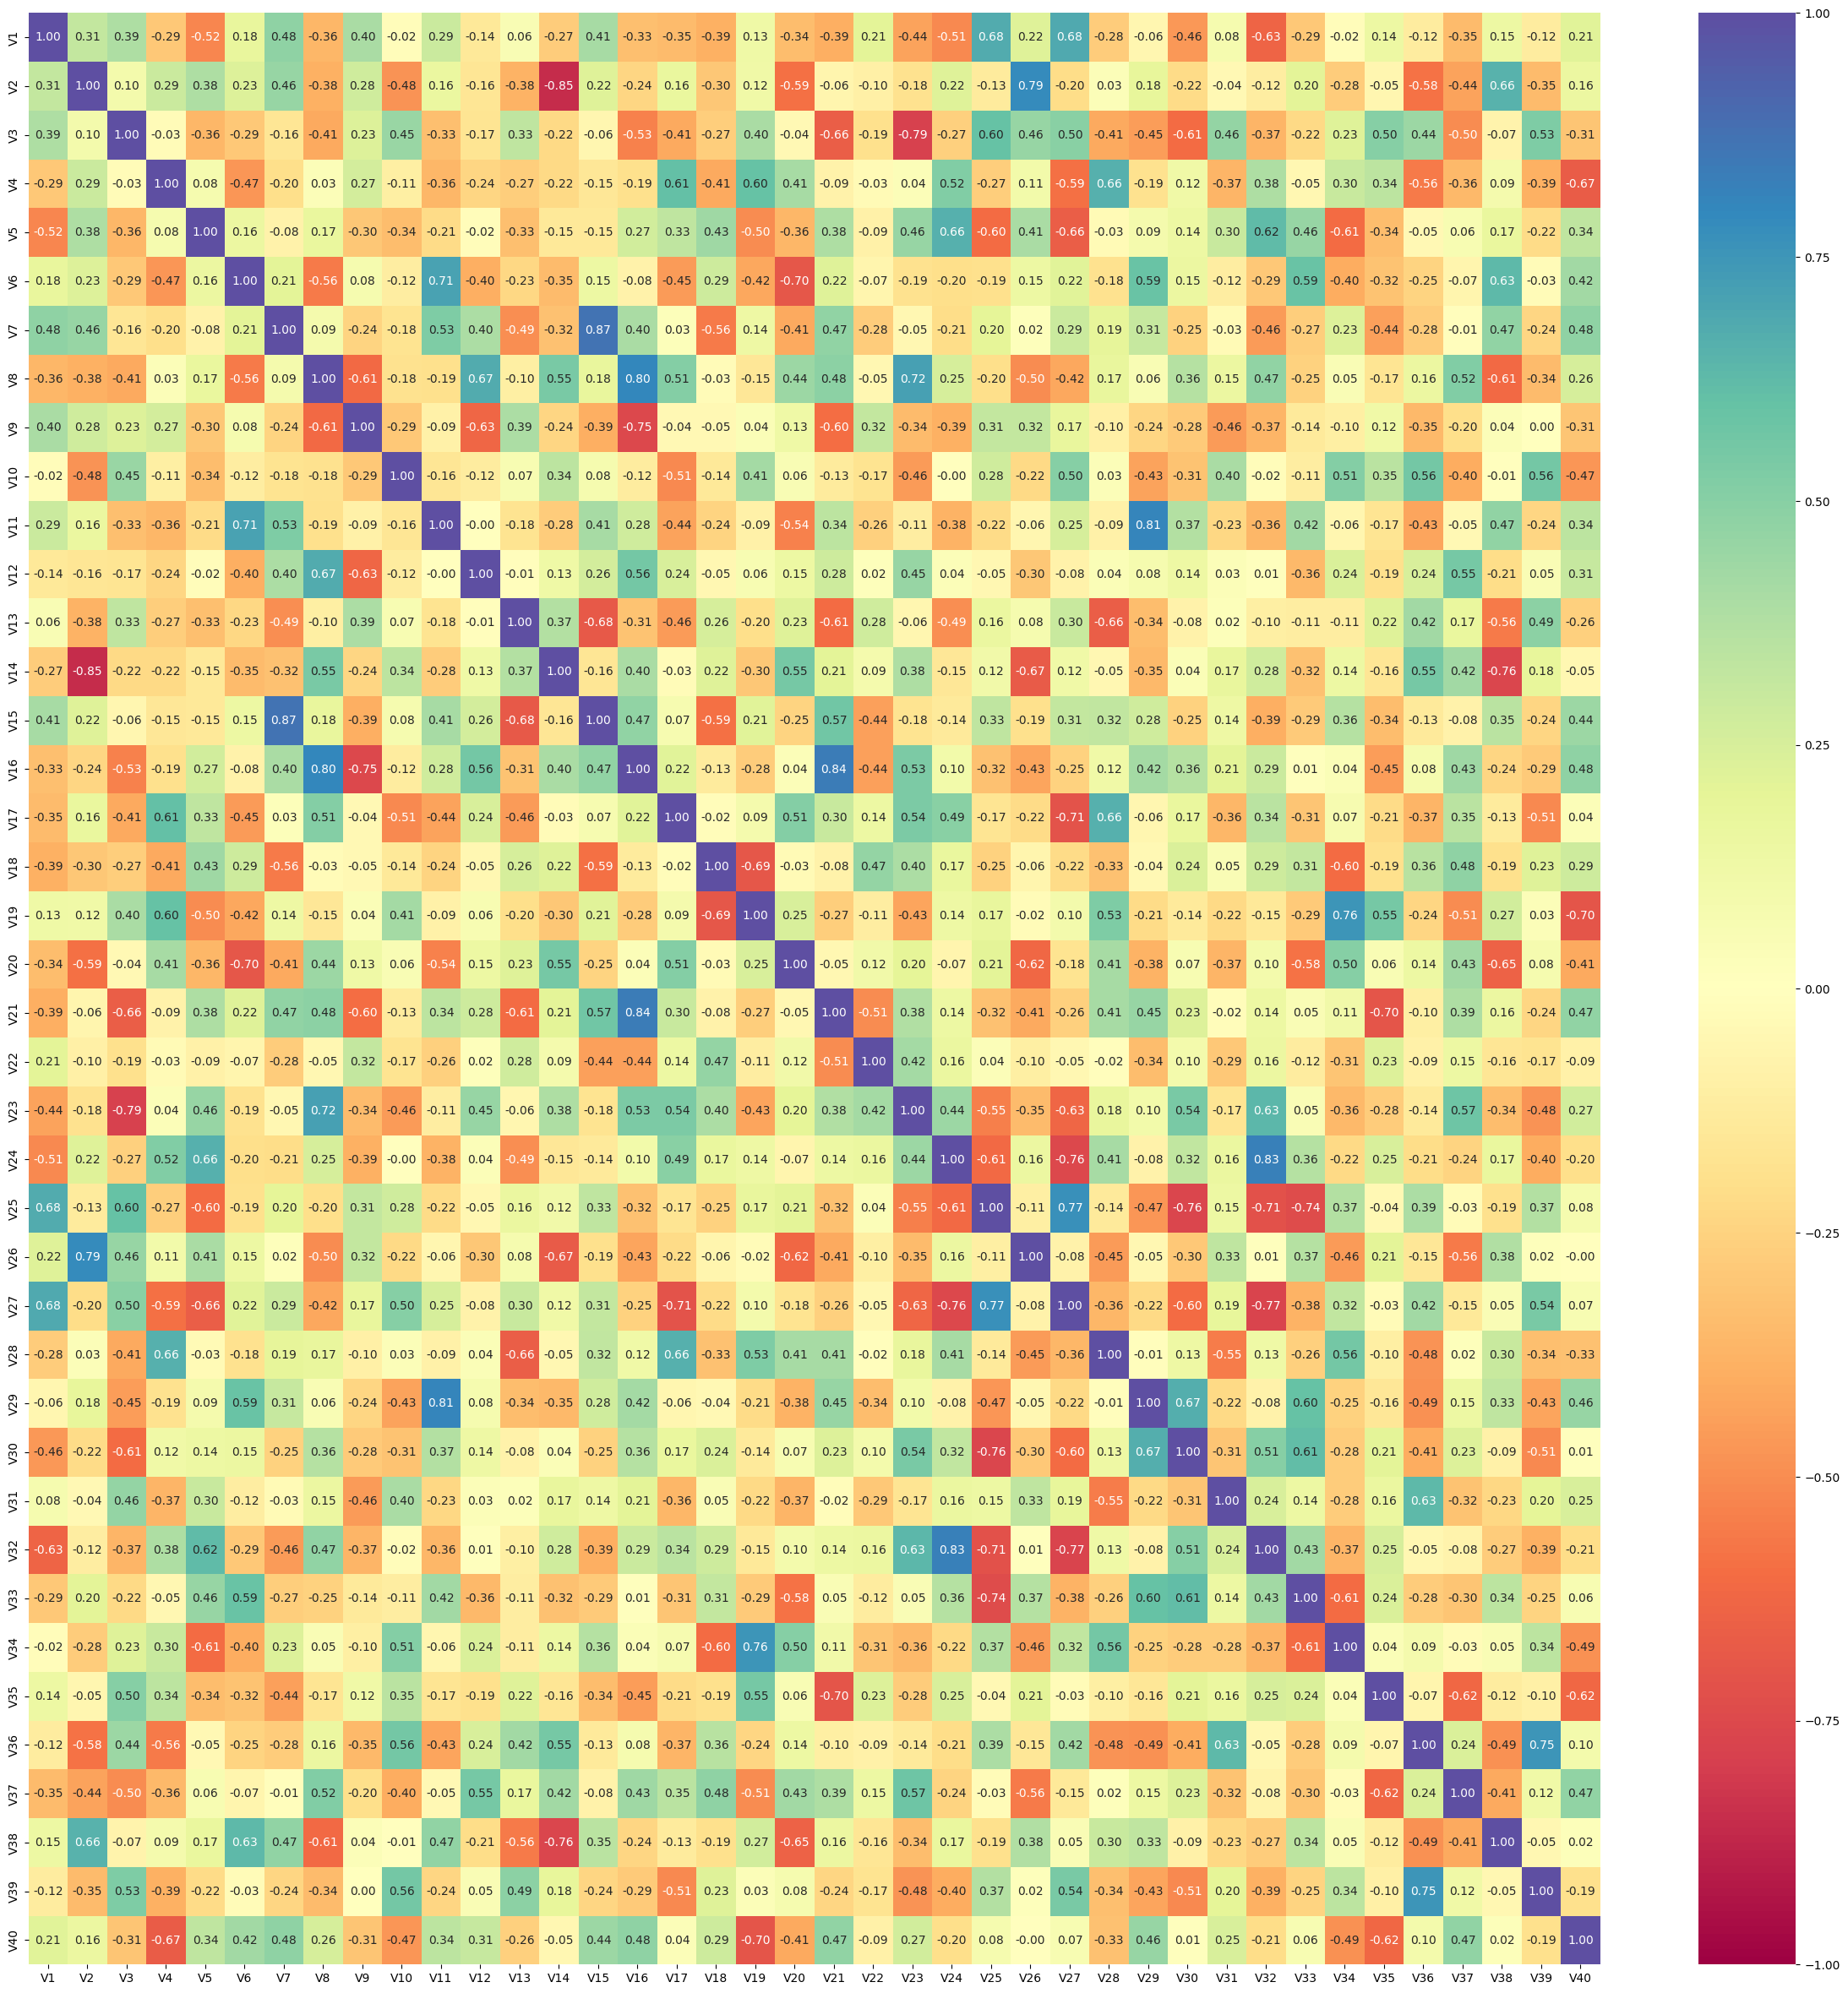

In [ ]:
plt.figure(figsize=(30, 30))
sns.heatmap(data[feature_cols].corr(), annot=True, vmin=-1, vmax=1, fmt=".2f", cmap="Spectral")
plt.show()

OBSERVATIONS:
- From the bivariant analysis via heatmap, we observe that:
  - Following variable pairs have strong positive corelation
    - V7 and V15 [+0.87]
    - V16 and V21 [+0.84]
    - V24 and V32 [+0.83]
    - V11 and V29 [+0.81]
    - V8 and V16 [+0.80]
    - V2 and V26 [+0.79]
    - V25 and V27 [+0.77]
    - V19 and V34 [+0.76]
    - V36 and V39 [+0.75]
    
  - Following variable pairs have strong negative corelation
    - V2 and V14 [-0.85]
    - V3 and V23 [-0.79]
    - V27 and V32 [-0.77]
    - V14 and V38 [-0.76]
    - V9 and V16 [-0.75]
    - V25 and V33 [-0.74]
    - V19 and V40 [-0.70]

- We also notice that while some features have high correlation, some have neglible correlation. So to give importance to the important features, L1 regularization (which has shrinking coefficients to prioritize more important features) can be experimented with.
- We eliminated the target variable in the heatmap to just compare the relations of the features only. Hence nothing can be deduced directly w.r.t. Target variable.

#### Check : Relation wrt target

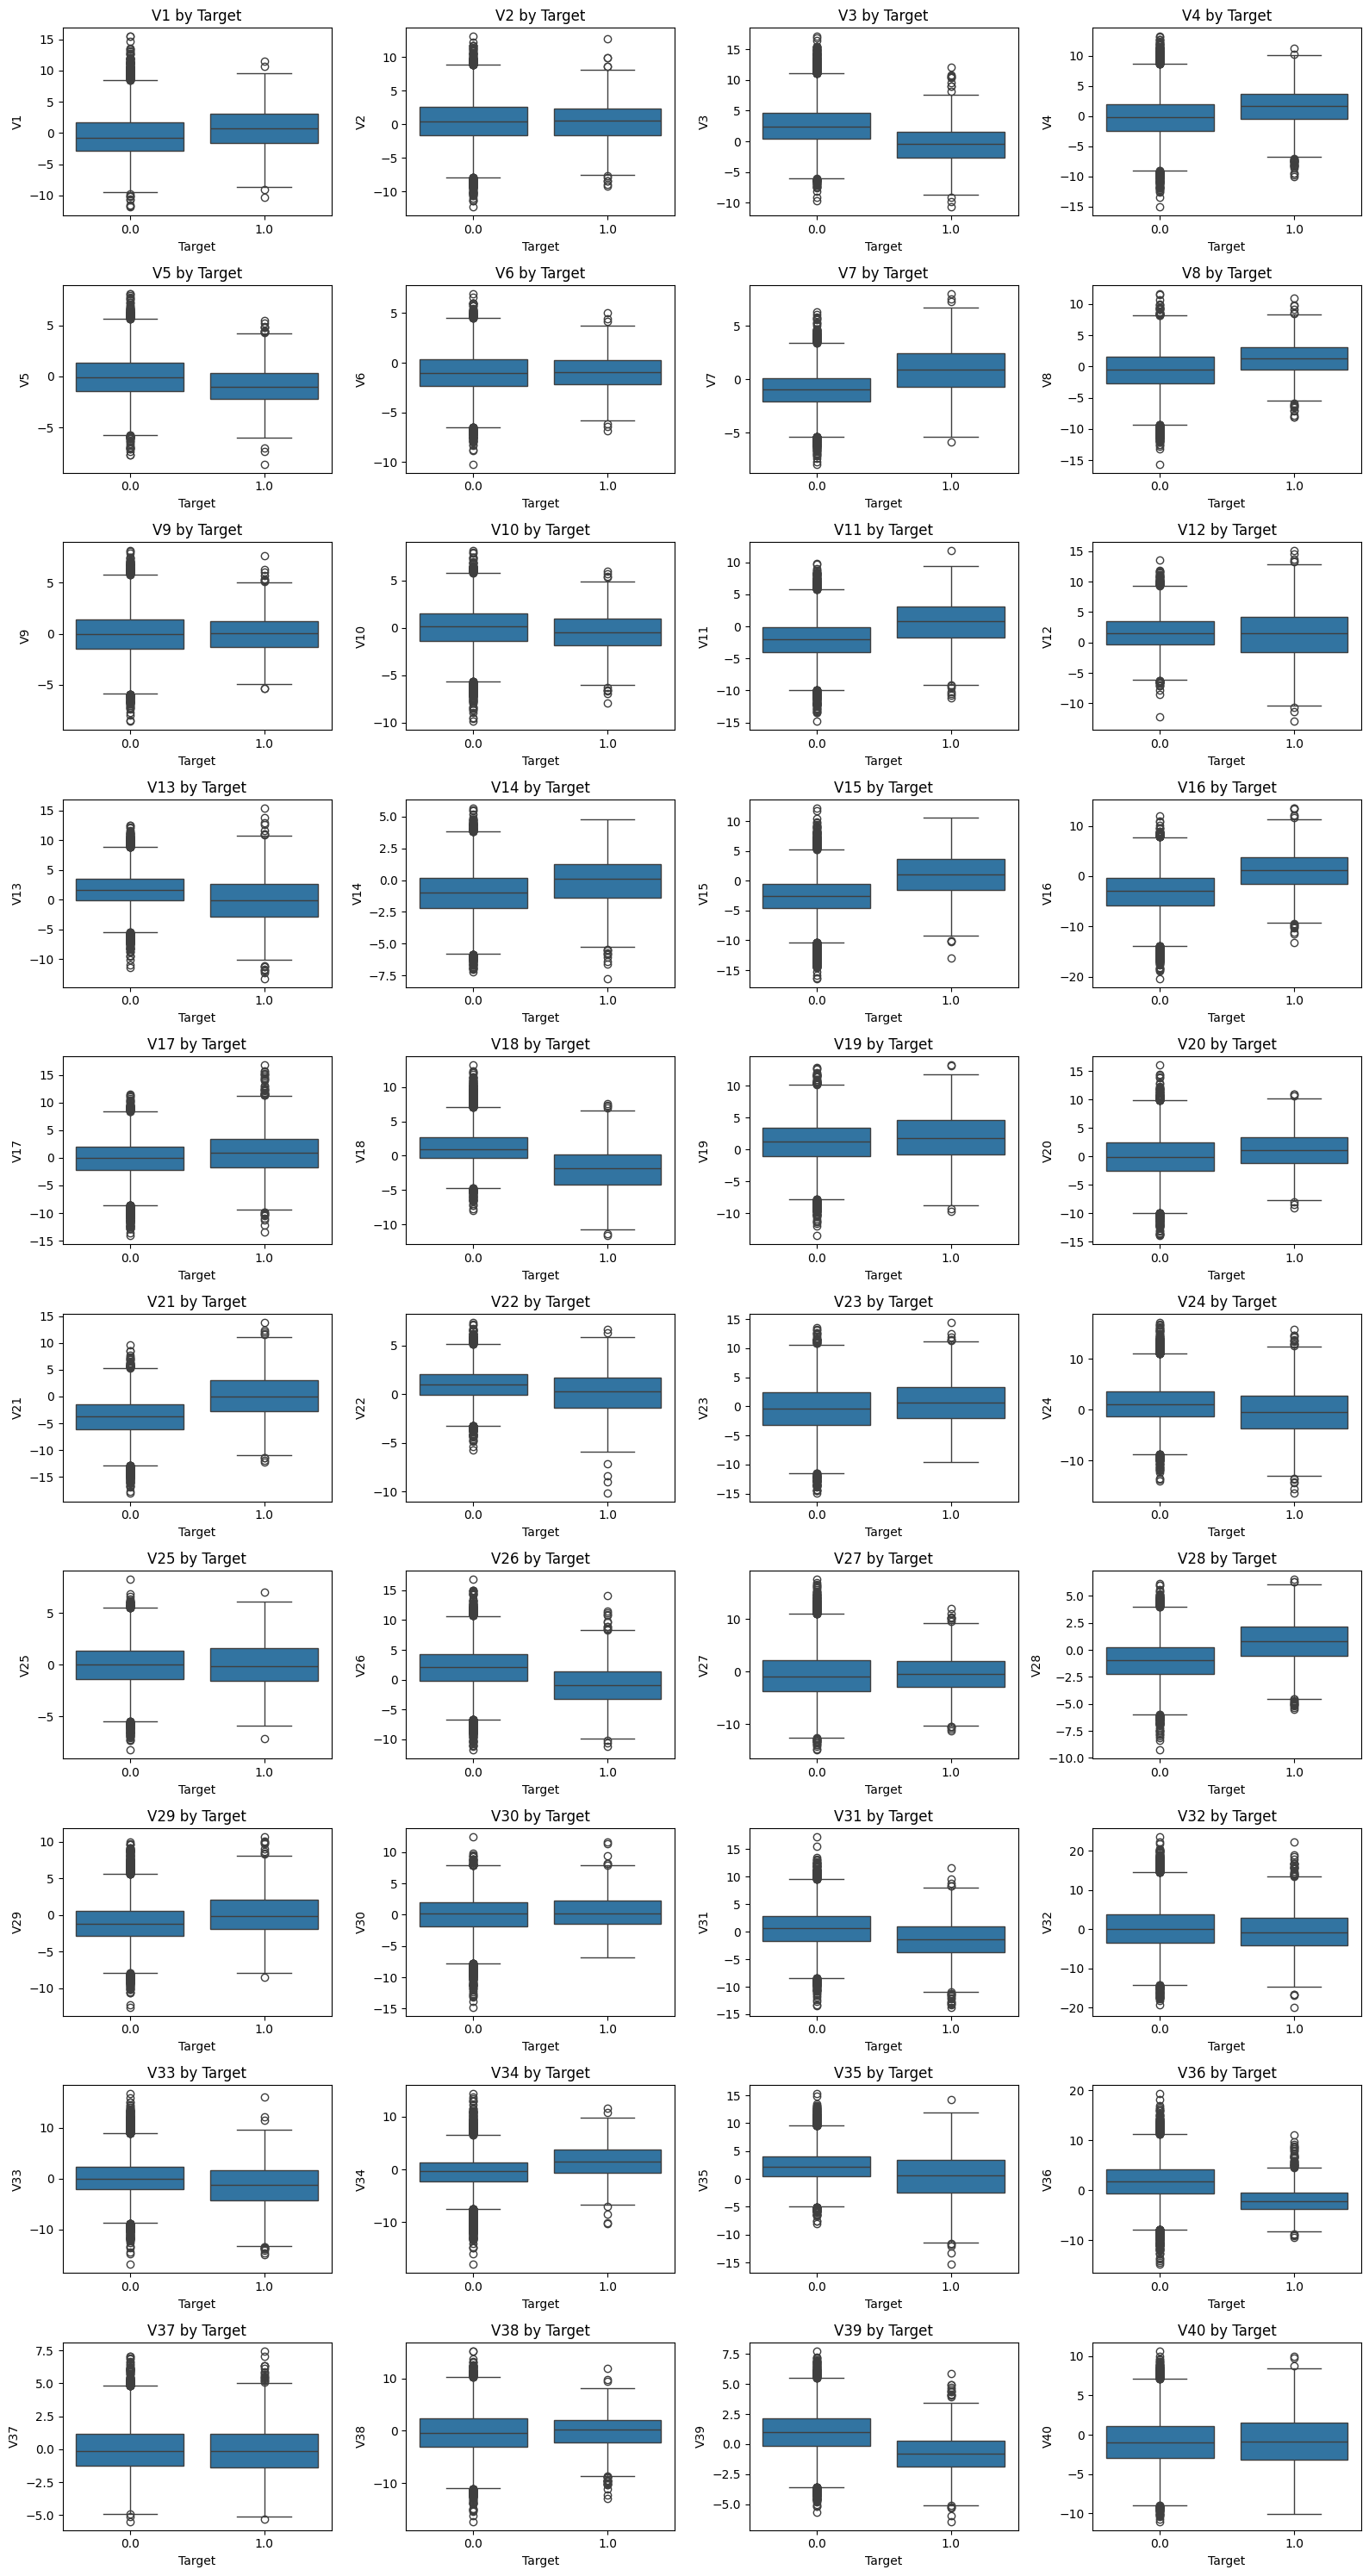

In [ ]:
plt.figure(figsize=(16, 30))

for i, col in enumerate(feature_cols):
    plt.subplot(10, 4, i + 1)
    sns.boxplot(x=data['Target'], y=data[col])
    plt.title(f'{col} by Target')
    plt.xlabel('Target')
    plt.ylabel(col)
plt.tight_layout()
plt.show()

OBSERVATIONS:


---

- Comparing each feature(V1-V40) against the 'Target' variable we can visualize for which ranges of each feature do the generators fail (1)
- For eg. for V39, from the box plot it seems like failures mostly happen if the value of V39 is less than 0.
- The data from sensors for mostly all features seems to be evenly distributed (no significant) with outliers for each of the features.
- It is difficult to infer a clear separation of a range of values for any of the features for which failures occur or not. Hence using machine learning models which while combine the permutations from all features will be helpful to predict failures which cannot be directly visible through individual feature plots.


# **Data Preprocessing**

### Data preparation for modeling

Training set

In [ ]:
X = data.drop('Target', axis=1)
y = data['Target']

In [ ]:
# Splitting data into training and validation set. We don't need testing split since we already have a separate testing set
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=1, stratify=y)

In [ ]:
X_train.shape, X_val.shape, y_train.shape, y_val.shape

((16000, 40), (4000, 40), (16000,), (4000,))

Testing Set

In [ ]:
# Dividing test data into X_test and y_test
X_test = data_test.drop(columns = ['Target'] , axis= 1)
y_test = data_test['Target']

In [ ]:
X_test.shape, y_test.shape

((5000, 40), (5000,))

### Missing value treatment

In [ ]:
imputer = SimpleImputer(strategy="median")

In [ ]:
# Fit and transform the train data
X_train = pd.DataFrame(imputer.fit_transform(X_train), columns=X_train.columns)

# Transform the validation data
X_val = pd.DataFrame(imputer.transform(X_val), columns=X_val.columns)

In [ ]:
# Transform the test data
X_test = pd.DataFrame(imputer.fit_transform(X_test), columns=X_test.columns)

OBSERVATIONS:


---

- By performing missing value treatment for training,validation and testing set separately, we ensure that there is no data leakage



In [ ]:
# Checking that no column has missing values in train or test sets
print(X_train.isna().sum())
print("---")
print(X_val.isna().sum())
print("---")
print(X_test.isna().sum())

V1     0
V2     0
V3     0
V4     0
V5     0
V6     0
V7     0
V8     0
V9     0
V10    0
V11    0
V12    0
V13    0
V14    0
V15    0
V16    0
V17    0
V18    0
V19    0
V20    0
V21    0
V22    0
V23    0
V24    0
V25    0
V26    0
V27    0
V28    0
V29    0
V30    0
V31    0
V32    0
V33    0
V34    0
V35    0
V36    0
V37    0
V38    0
V39    0
V40    0
dtype: int64
---
V1     0
V2     0
V3     0
V4     0
V5     0
V6     0
V7     0
V8     0
V9     0
V10    0
V11    0
V12    0
V13    0
V14    0
V15    0
V16    0
V17    0
V18    0
V19    0
V20    0
V21    0
V22    0
V23    0
V24    0
V25    0
V26    0
V27    0
V28    0
V29    0
V30    0
V31    0
V32    0
V33    0
V34    0
V35    0
V36    0
V37    0
V38    0
V39    0
V40    0
dtype: int64
---
V1     0
V2     0
V3     0
V4     0
V5     0
V6     0
V7     0
V8     0
V9     0
V10    0
V11    0
V12    0
V13    0
V14    0
V15    0
V16    0
V17    0
V18    0
V19    0
V20    0
V21    0
V22    0
V23    0
V24    0
V25    0
V26    0
V27    0
V28

In [ ]:
y_train = y_train.to_numpy()
y_val = y_val.to_numpy()
y_test = y_test.to_numpy()

OBSERVATIONS:

---

- Since we noticed some missing values in V1 and V2, we used Simple Imputer to treat the missing values with the median. Used median because from the univariant analysis earlier, we observed that the data for V1 and V2 is mostly evenly distributed.



# **Model Building**

## Model Evaluation Criterion

- Our goal is to identify if there will be a machine error or not ( 1 or 0) Hence it is a classification problem.
- Secondly, since the cost of replacement is the highest which corresponds to False Negatives(FN) , we should aim to reduce that cost, hence minimize FN. The best score for evaluating that is *recall score* since it aims to predict the True Negatives(TN) correctly. So we will choose recall score to evaluate all our models
- Technical details:
  - Since our output is 0/1 we will use sigmoid activation function for output layer.
  - For the same reason, we can experiment with ReLU and sigmoid functions in the hidden layers
  - The other experiments we can check on for building different models are:
    - Introducing Hidden Layers and change the number of layers
    - Changing the number of neurons.
    - Dropout
    - Batch Normalization
    - Changing optimizers: SGD, Adam
    - Introducing class weights since the classes for 0 and 1 are imbalanced from our Data analysis
    - Regularilzation
    - I also plan to change the threshold to test.

## Utility Functions

In [ ]:
def plot(history, name):
    """
    Function to plot loss/accuracy

    history: an object which stores the metrics and losses.
    name: can be one of Loss or Accuracy
    """
    fig, ax = plt.subplots() #Creating a subplot with figure and axes.
    plt.plot(history.history[name]) #Plotting the train accuracy or train loss
    plt.plot(history.history['val_'+name]) #Plotting the validation accuracy or validation loss

    plt.title('Model ' + name.capitalize()) #Defining the title of the plot.
    plt.ylabel(name.capitalize()) #Capitalizing the first letter.
    plt.xlabel('Epoch') #Defining the label for the x-axis.
    fig.legend(['Train', 'Validation'], loc="outside right upper") #Defining the legend, loc controls the position of the legend.

In [ ]:
# defining a function to compute different metrics to check performance of a classification model built using statsmodels
def model_performance_classification(
    model, predictors, target, threshold=0.5
):
    """
    Function to compute different metrics to check classification model performance

    model: classifier
    predictors: independent variables
    target: dependent variable
    threshold: threshold for classifying the observation as class 1
    """

    # checking which probabilities are greater than threshold
    pred = model.predict(predictors) > threshold
    # pred_temp = model.predict(predictors) > threshold
    # # rounding off the above values to get classes
    # pred = np.round(pred_temp)

    acc = accuracy_score(target, pred)  # to compute Accuracy
    recall = recall_score(target, pred, average='macro')  # to compute Recall
    precision = precision_score(target, pred, average='macro')  # to compute Precision
    f1 = f1_score(target, pred, average='macro')  # to compute F1-score

    # creating a dataframe of metrics
    df_perf = pd.DataFrame(
        {"Accuracy": acc, "Recall": recall, "Precision": precision, "F1 Score": f1,}, index = [0]
    )

    return df_perf

## Initial Model Building (Model 0)

Let's start with a base Model 0 of neural network

<table >
<thead>
<th> Hidden Layers</th>
<th> Neurons </th>
<th> Optimiser</th>
<th> Normalization </th>
<th> Regularization/Dropout</th>
<th> Class Weight Distribution</th>
</thead>
<tbody>
<tr>
<td> 1</td>
<td> 14 </td>
<td> SGD</td>
<td> - </td>
<td> - </td>
<td> - </td>
</tr>
</tbody>
</table>



---


---


For our models we will be initializing:

<table>
<thead>
<th> Hidden Layer Activation Function</th>
<th> O/P Layer Activation function </th>
<th> Epoch</th>
<th> Batch size </th>
<th> Threshold for classification</th>
</thead>
<tbody>
<tr>
<td> ReLU (values: max(0,x))</td>
<td> Sigmoid (values: 0/1) </td>
<td> 30</td>
<td> 400 </td>
<td> 0.5 </td>
</tr>
</tbody>
</table>


In [ ]:
#defining initializing variables
epochs = 30
batch_size = 400 # since there are total ~16000 training and ~4000 validation records
threshold = 0.5

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 14)             │           574 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            15 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 589 (2.30 KB)

 Trainable params: 589 (2.30 KB)

 Non-trainable params: 0 (0.00 B)

None
Epoch 1/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - Recall: 0.0585 - loss: 0.4239 - val_Recall: 0.1261 - val_loss: 0.2852
Epoch 2/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - Recall: 0.1346 - loss: 0.2560 - val_Recall: 0.2072 - val_loss: 0.2284
Epoch 3/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - Recall: 0.1987 - loss: 0.2096 - val_Recall: 0.2658 - val_loss: 0.1994
Epoch 4/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - Recall: 0.2631 - loss: 0.1838 - val_Recall: 0.3288 - val_loss: 0.1808
Epoch 5/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - Recall: 0.2984 - loss: 0.1667 - val_Recall: 0.3559 - val_loss: 0.1674
Epoch 6/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - Recall: 0.3427 - loss: 0.1543 - val_Recall: 0.3649 - val_loss: 0.1572
Epoch 7/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - Recall: 0.3642 - loss: 0.1448 - val_Recall: 0.3874 - val_loss: 0.1491
Epoch 8/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - Recall: 0.4004 - loss: 0.1374 - val_Recall: 0.3964 - val_loss: 0.1425
Epoch 9/30
40/40 ━━

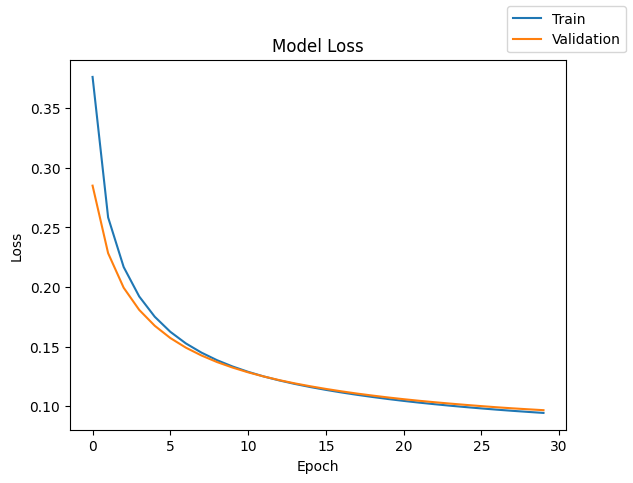

In [ ]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(1618)

#Initializing the neural network
model_0 = Sequential()
model_0.add(Dense(14,activation="relu",input_dim=X_train.shape[1]))
model_0.add(Dense(1,activation="sigmoid"))

print(model_0.summary())

optimizer = tf.keras.optimizers.SGD()   # defining SGD as the optimizer to be used
model_0.compile(loss='binary_crossentropy', optimizer=optimizer, metrics = ['Recall'])

start = time.time()
history = model_0.fit(X_train, y_train, validation_data=(X_val,y_val) , batch_size=batch_size, epochs=epochs)
end=time.time()

print("Time taken in seconds ",end-start)

plot(history,'loss')

### Model performance of model_0 on training and validation data

In [ ]:
model_0_train_perf = model_performance_classification(model_0, X_train, y_train)
model_0_train_perf

500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step


,Accuracy,Recall,Precision,F1 Score
0,0.976063,0.804486,0.95611,0.863367


In [ ]:
model_0_val_perf = model_performance_classification(model_0,X_val,y_val)
model_0_val_perf

125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  


,Accuracy,Recall,Precision,F1 Score
0,0.978,0.823001,0.957392,0.877207


In [ ]:
y_train_pred_0 = model_0.predict(X_train)
y_val_pred_0 = model_0.predict(X_val)

500/500 ━━━━━━━━━━━━━━━━━━━━ 0s 939us/step
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  


OBSERVATIONS 1 of 2:

---
- **Evaluation parameters:**
  - Recall is ~0.80 and ~0.82 on training and validation set. This is a **good recall** score. We can try to optimize this further
  - Accuracy is ~0.98 for both and F1-score is also ~0.88 which indicates good prediction and **good generalisation**

- **Epoch and Loss function:**
  - Seems like the graph will get flatter after epoch 25 or so, meaning that learning will not happen after that. Hence our chosen **epoch value seems to be appropriate** to use it for further models. Though we can try to increase it slightly.
  - The loss value converges later meaning for further which means that this model **may cause overfitting** for more epoch or unknown data.

### Classification report of model_0 on training and validation data

In [ ]:
print("\n Classification Report - Train data Model_0",end="\n\n")
cr_train_model_0 = classification_report(y_train,y_train_pred_0> threshold)
print(cr_train_model_0)

print("\n Classification Report - Validation data Model_0",end="\n\n")
cr_val_model_0 = classification_report(y_val,y_val_pred_0> threshold)
print(cr_val_model_0)


 Classification Report - Train data Model_0

              precision    recall  f1-score   support

         0.0       0.98      1.00      0.99     15112
         1.0       0.93      0.61      0.74       888

    accuracy                           0.98     16000
   macro avg       0.96      0.80      0.86     16000
weighted avg       0.98      0.98      0.97     16000


 Classification Report - Validation data Model_0

              precision    recall  f1-score   support

         0.0       0.98      1.00      0.99      3778
         1.0       0.94      0.65      0.77       222

    accuracy                           0.98      4000
   macro avg       0.96      0.82      0.88      4000
weighted avg       0.98      0.98      0.98      4000



OBSERVATIONS 2 of 2:

---

- For **Initial Model 0**, recall score is very poor for predicting error (1.0). It is: 0.61 and 0.65 for training and testing data respectively
- F1-score is average on both datasets ( ~ 0.7) and precision is good( ~ 0.93) for predicting errors.  
- The validation performance is better than training.Hence the model is not overfitting.
---
- We have a rough idea on our parameters now which we can use as a base of optimizing.
- Let us add additional parameters to improve the next model. Also, since the class for failure is imbalances w.r.t. no failures, we can add class weights to minimise bias



# **Model Performance Improvement**

## Model 1

<table >
<thead>
<th> Hidden Layers</th>
<th> Neurons </th>
<th> Optimiser</th>
<th> Normalization </th>
<th> Regularization/Dropout</th>
<th> Class Weight Distribution</th>
</thead>
<tbody>
<tr>
<td> 2</td>
<td> 14 ,7</td>
<td> SGD</td>
<td> - </td>
<td> - </td>
<td> Yes </td>
</tr>
</tbody>
</table>


- As we have are dealing with an imbalance in class distribution, we should also be using class weights to allow the model to give proportionally more importance to the minority class.
- Also increasing epoch a little for optimization

In [ ]:
epochs = 40

In [ ]:
# Calculate class weights for imbalanced dataset
cw = (y_train.shape[0]) / np.bincount(y_train.astype(int)) # Convert y_train to integers

# Create a dictionary mapping class indices to their respective class weights
cw_dict = {}
for i in range(cw.shape[0]):
    cw_dict[i] = cw[i]

cw_dict

{0: np.float64(1.0587612493382743), 1: np.float64(18.01801801801802)}

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 14)             │           574 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           105 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             8 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 687 (2.68 KB)

 Trainable params: 687 (2.68 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - Recall: 0.6153 - loss: 1.3800 - val_Recall: 0.8874 - val_loss: 0.6570
Epoch 2/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - Recall: 0.8834 - loss: 1.0126 - val_Recall: 0.8784 - val_loss: 0.5364
Epoch 3/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - Recall: 0.8814 - loss: 0.8619 - val_Recall: 0.8784 - val_loss: 0.4692
Epoch 4/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - Recall: 0.9035 - loss: 0.7703 - val_Recall: 0.8874 - val_loss: 0.4210
Epoch 5/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - Recall: 0.9023 - loss: 0.7052 - val_Recall: 0.8874 - val_loss: 0.3830
Epoch 6/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - Recall: 0.9049 - loss: 0.6559 - val_Recall: 0.8919 - val_loss: 0.3495
Epoch 7/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - Recall: 0.9033 - loss: 0.6166 - val_Recall: 0.8829 - val_loss: 0.3219
Epoch 8/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - Recall: 0.8986 - loss: 0.5834 - val_Recall: 0.8784 - val_loss: 0.2997
Epoch 9/40
40/40 ━━━━━━

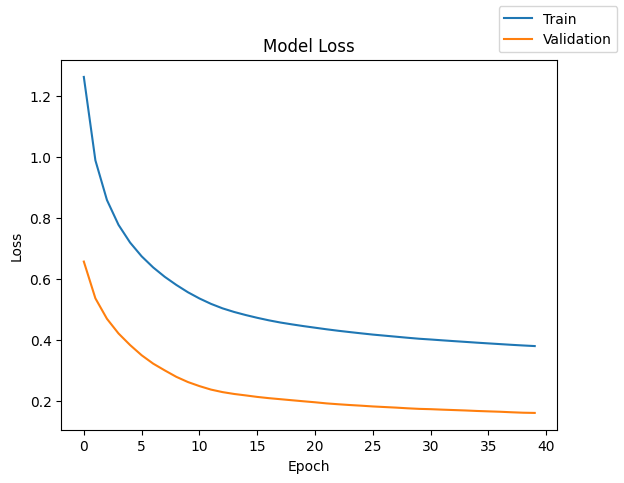

In [ ]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(1618)

#Initializing the neural network
model_1 = Sequential()
model_1.add(Dense(14 ,activation="relu",input_dim=X_train.shape[1]))
model_1.add(Dense(7,activation="relu"))
model_1.add(Dense(1,activation="sigmoid"))

model_1.summary()

optimizer = tf.keras.optimizers.SGD()   # defining SGD as the optimizer to be used
model_1.compile(loss='binary_crossentropy', optimizer=optimizer, metrics = ['Recall'])

start = time.time()
history = model_1.fit(X_train, y_train, validation_data=(X_val,y_val) , batch_size=batch_size, epochs=epochs, class_weight=cw_dict)
end=time.time()

print("Time taken in seconds ",end-start)

plot(history,'loss')

### Model performance of model_1 on training and validation data

In [ ]:
model_1_train_perf = model_performance_classification(model_1,X_train,y_train)
model_1_train_perf

500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step  


,Accuracy,Recall,Precision,F1 Score
0,0.96875,0.941059,0.826282,0.873487


In [ ]:
model_1_val_perf = model_performance_classification(model_1,X_val,y_val)
model_1_val_perf

125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  


,Accuracy,Recall,Precision,F1 Score
0,0.97075,0.929398,0.837962,0.877259


In [ ]:
y_train_pred_1 = model_1.predict(X_train)
y_val_pred_1 = model_1.predict(X_val)

500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step  
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


OBSERVATIONS 1 of 2:

---
- **Evaluation parameters:**
  - **Optimal Recall score**: : ~0.94 and ~0.93 on training and validation set for the model.
  - Accuracy is ~0.97 for both and F1-score is also ~0.87 which indicates good prediction.

- **Epoch and Loss function:**
  - Seems like the graph will get flatter after epoch 30 or so, meaning that learning will not happen after that. Hence will retain this epoch value of 40.
  - The **model is learning well** as the loss decreases for both training and validation sets over the epochs.
  - The **model is generalising very well** because the training and validation set lines in the graph are decreasing parallely.

### Classification report of model_1 on training and validation data

In [ ]:
print("Classification Report - Train data Model_1", end="\n\n")
cr_train_model_1 = classification_report(y_train,y_train_pred_1 > threshold)
print(cr_train_model_1)

print("Classification Report - Validation data Model_1", end="\n\n")
cr_val_model_1 = classification_report(y_val,y_val_pred_1 > threshold)
print(cr_val_model_1)

Classification Report - Train data Model_1

              precision    recall  f1-score   support

         0.0       0.99      0.97      0.98     15112
         1.0       0.66      0.91      0.76       888

    accuracy                           0.97     16000
   macro avg       0.83      0.94      0.87     16000
weighted avg       0.98      0.97      0.97     16000

Classification Report - Validation data Model_1

              precision    recall  f1-score   support

         0.0       0.99      0.98      0.98      3778
         1.0       0.68      0.88      0.77       222

    accuracy                           0.97      4000
   macro avg       0.84      0.93      0.88      4000
weighted avg       0.98      0.97      0.97      4000



OBSERVATIONS 2 of 2:

---

- For **Model 1**, **recall score has improved significantly** for predicting errors by adding class weights. It is: 0.91 and 0.89 for training and testing data respectively
- F1-score is average on both datasets ( ~ 0.7) and accuracy is good( ~ 0.9) for predicting errors.
- The validation performance is lower than training. Hence the model is **slightly overfitting**.
---

- We learnt that adding class weights helps the model reduce bias and improve significantly. So we will retain that for future.
- Also, to get more learning from our model, let us add SGD with momentum and additional hidden layer for the next model

## Model 2

<table >
<thead>
<th> Hidden Layers</th>
<th> Neurons </th>
<th> Optimiser</th>
<th> Normalization </th>
<th> Regularization/Dropout</th>
<th> Class Weight Distribution</th>
</thead>
<tbody>
<tr>
<td> 3</td>
<td> 32, 16, 8</td>
<td> SGD with momentum 0.9</td>
<td> - </td>
<td> After first layer, dropout:50% </td>
<td> Yes </td>
</tr>
</tbody>
</table>


- To optimise learning, we are additing SGD with momentum and an additional hidden layer.
- Further to generalise better, let's experiment with adding a drop of of 50% of the features after first layer

In [ ]:
# clear the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(1618)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │         1,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,985 (7.75 KB)

 Trainable params: 1,985 (7.75 KB)

 Non-trainable params: 0 (0.00 B)

None
Epoch 1/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - Recall: 0.5838 - loss: 1.4935 - val_Recall: 0.8333 - val_loss: 0.3734
Epoch 2/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - Recall: 0.8011 - loss: 0.8017 - val_Recall: 0.8784 - val_loss: 0.3902
Epoch 3/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - Recall: 0.8454 - loss: 0.6748 - val_Recall: 0.8739 - val_loss: 0.3023
Epoch 4/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - Recall: 0.8411 - loss: 0.6083 - val_Recall: 0.8874 - val_loss: 0.3333
Epoch 5/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - Recall: 0.8506 - loss: 0.5456 - val_Recall: 0.8739 - val_loss: 0.3120
Epoch 6/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - Recall: 0.8510 - loss: 0.5577 - val_Recall: 0.8739 - val_loss: 0.2344
Epoch 7/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - Recall: 0.8634 - loss: 0.5288 - val_Recall: 0.8874 - val_loss: 0.2511
Epoch 8/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - Recall: 0.8599 - loss: 0.5035 - val_Recall: 0.8784 - val_loss: 0.2324
Epoch 9/40
40/40 ━

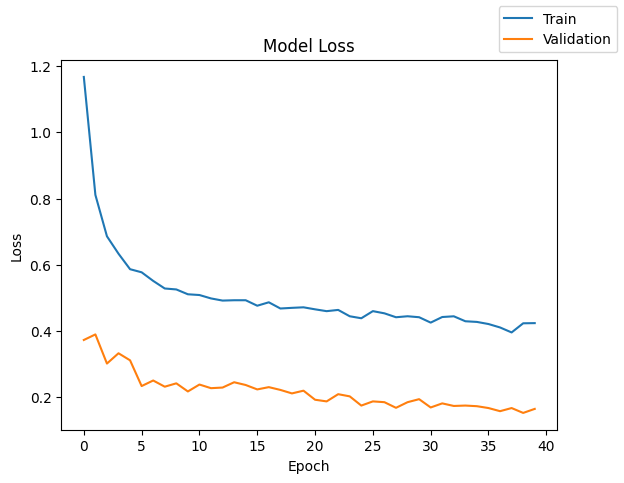

In [ ]:
#Initializing the neural network
model_2 = Sequential()
model_2.add(Dense(32,activation="relu",input_dim=X_train.shape[1]))
model_2.add(Dropout(0.5))
model_2.add(Dense(16,activation = "relu"))
model_2.add(Dense(8,activation = "relu"))
model_2.add(Dense(1,activation="sigmoid"))

print(model_2.summary())

optimizer = tf.keras.optimizers.SGD(momentum=0.9)   # defining SGD as the optimizer to be used with momentum of 0.9
model_2.compile(loss='binary_crossentropy', optimizer=optimizer, metrics = ['Recall'])

start = time.time()
history = model_2.fit(X_train, y_train, validation_data=(X_val,y_val) , batch_size=batch_size, epochs=epochs, class_weight=cw_dict)
end=time.time()

print("Time taken in seconds ",end-start)

plot(history,'loss')

### Model performance of model_2 on training and validation data

In [ ]:
model_2_train_perf = model_performance_classification(model_2,X_train,y_train)
model_2_train_perf

500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step  


,Accuracy,Recall,Precision,F1 Score
0,0.982313,0.943999,0.899078,0.920156


In [ ]:
model_2_val_perf = model_performance_classification(model_2,X_val,y_val)
model_2_val_perf

125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  


,Accuracy,Recall,Precision,F1 Score
0,0.98275,0.93999,0.904213,0.921228


In [ ]:
y_train_pred_2 = model_2.predict(X_train)
y_val_pred_2 = model_2.predict(X_val)

500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


OBSERVATIONS 1 of 2:

---
- **Evaluation parameters:**
  - **Optimal Recall score** is retained from the previous model. Here it is : ~0.94 and ~0.93 on training and validation set for the model 2.
  - Accuracy is ~0.98 for both and F1-score is also ~0.92 which indicates significant improvement!

- **Epoch and Loss function:**
  - The validation loss on training data flattens on last 3-4 epochs. Hence our epoch is optimal for this model.
  - The **model is learning better** than the previous model, because even though there are fluctuations, our metrics are better with similar loss valuations.
  - The loss decreases for both training and validation sets over the epochs.
  - The model is generalising very well because the training and validation set lines in the graph are decreasing parallely.

### Classification report of model_2 on training and validation data

In [ ]:
print("Classification Report - Train data Model_2", end="\n\n")
cr_train_model_2 = classification_report(y_train,y_train_pred_2 > threshold)
print(cr_train_model_2)

print("Classification Report - Validation data Model_2", end="\n\n")
cr_val_model_2 = classification_report(y_val , y_val_pred_2 > threshold)
print(cr_val_model_2)

Classification Report - Train data Model_2

              precision    recall  f1-score   support

         0.0       0.99      0.99      0.99     15112
         1.0       0.80      0.90      0.85       888

    accuracy                           0.98     16000
   macro avg       0.90      0.94      0.92     16000
weighted avg       0.98      0.98      0.98     16000

Classification Report - Validation data Model_2

              precision    recall  f1-score   support

         0.0       0.99      0.99      0.99      3778
         1.0       0.81      0.89      0.85       222

    accuracy                           0.98      4000
   macro avg       0.90      0.94      0.92      4000
weighted avg       0.98      0.98      0.98      4000



OBSERVATIONS 2 of 2:

---


- For **Model 2**, **recall score is similar to previous model** for predicting errors by adding class weights. It is: 0.90 and 0.88 for training and testing data respectively
- F1-score is average on both datasets ( ~ 0.8) and precision is average( ~ 0.7) for predicting errors.
- The validation performance is lower than training. Hence the model is **slightly overfitting**.

---

- We learnt that by adding Dropout, SGD with momentum, and a hidden layer although our performance is similar for predicting error, the model is learning better. So we can experiment by tweaking these parameters for next model
- Also let's add Batch Normalization.

## Model 3

<table >
<thead>
<th> Hidden Layers</th>
<th> Neurons </th>
<th> Optimiser</th>
<th> Normalization </th>
<th> Regularization/Dropout</th>
<th> Class Weight Distribution</th>
</thead>
<tbody>
<tr>
<td> 3</td>
<td> 32, 16, 8 </td>
<td> SGD with momentum 0.9 </td>
<td> Batch after each Hlayer </td>
<td> 1st HLayer: 40%, 2nd HLayer: 10%  </td>
<td> Yes </td>
</tr>
</tbody>
</table>


- As mentioned, we will add Batch normalization
- Running the following code with some changing numbers of neurons, momentum , dropout and other parameters and retaining the optimal

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │         1,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 8)              │            32 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,209 (8.63 KB)

 Trainable params: 2,097 (8.19 KB)

 Non-trainable params: 112 (448.00 B)

None
Epoch 1/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - Recall: 0.7438 - loss: 1.3018 - val_Recall: 0.8288 - val_loss: 0.2728
Epoch 2/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - Recall: 0.8032 - loss: 0.6977 - val_Recall: 0.8739 - val_loss: 0.2500
Epoch 3/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - Recall: 0.8371 - loss: 0.6186 - val_Recall: 0.8919 - val_loss: 0.2349
Epoch 4/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - Recall: 0.8402 - loss: 0.5862 - val_Recall: 0.8739 - val_loss: 0.2130
Epoch 5/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - Recall: 0.8655 - loss: 0.5404 - val_Recall: 0.8694 - val_loss: 0.1773
Epoch 6/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - Recall: 0.8598 - loss: 0.5337 - val_Recall: 0.8784 - val_loss: 0.1768
Epoch 7/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - Recall: 0.8750 - loss: 0.5042 - val_Recall: 0.8829 - val_loss: 0.1856
Epoch 8/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - Recall: 0.8781 - loss: 0.4816 - val_Recall: 0.8739 - val_loss: 0.1623
Epoch 9/40
40/40 ━

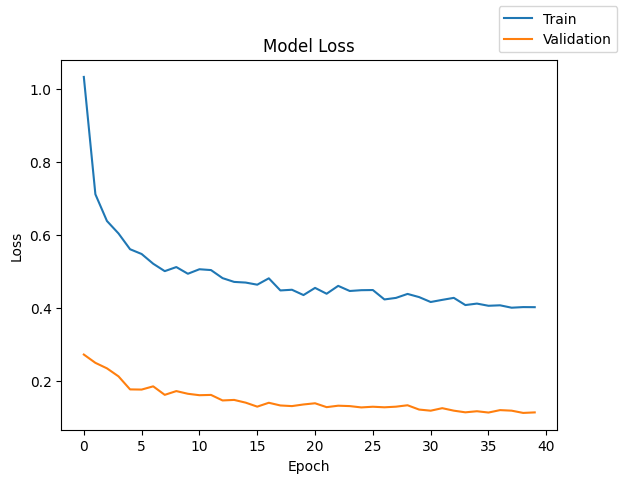

In [ ]:
# clear the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(1618)

model_3 = Sequential()
model_3.add(Dense(32,activation="relu",input_dim=X_train.shape[1]))
model_3.add(BatchNormalization())
model_3.add(Dropout(0.4))
model_3.add(Dense(16,activation="relu"))
model_3.add(BatchNormalization())
model_3.add(Dropout(0.1))
model_3.add(Dense(8, activation = "relu"))
model_3.add(BatchNormalization())
model_3.add(Dense(1,activation="sigmoid"))

print(model_3.summary())

optimizer = tf.keras.optimizers.SGD(momentum= 0.9)   # defining SGD as the optimizer to be used
model_3.compile(loss='binary_crossentropy', optimizer=optimizer, metrics = ['Recall'])

start = time.time()
history = model_3.fit(X_train, y_train, validation_data=(X_val,y_val) , batch_size=batch_size, epochs=epochs,class_weight=cw_dict)
end=time.time()

print("Time taken in seconds ",end-start)

plot(history,'loss')

### Model performance of model_3 on training and validation data

In [ ]:
model_3_train_perf = model_performance_classification(model_3,X_train,y_train)
model_3_train_perf

500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step


,Accuracy,Recall,Precision,F1 Score
0,0.984938,0.949628,0.914263,0.931113


In [ ]:
model_3_val_perf = model_performance_classification(model_3,X_val,y_val)
model_3_val_perf

125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


,Accuracy,Recall,Precision,F1 Score
0,0.985,0.939062,0.921252,0.929945


In [ ]:
y_train_pred_3 = model_3.predict(X_train)
y_val_pred_3 = model_3.predict(X_val)

500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


OBSERVATIONS 1 of 2:

---
- **Evaluation parameters:**
  - **Optimal Recall score**: : ~0.95 and ~0.94 on training and validation set for the model.
  - **All scores are near best** for a model as they are >0.9 with accuracy at 0.98! This seems to be one of the promising models to be considered!

- **Epoch and Loss function:**
  
  - The **model is learning well** as the loss decreases for both training and validation sets over the epochs. Also since the scores are near same for training and validation set, this model is **generalising optimally** too!

### Classification report of model_3 on training and validation data

In [ ]:
print("Classification Report - Train data Model_3", end="\n\n")
cr_train_model_3 = classification_report(y_train,y_train_pred_3 > threshold)
print(cr_train_model_3)

print("Classification Report - Validation data Model_3", end="\n\n")
cr_val_model_3 = classification_report(y_val,y_val_pred_3 > threshold)
print(cr_val_model_3)

Classification Report - Train data Model_3

              precision    recall  f1-score   support

         0.0       0.99      0.99      0.99     15112
         1.0       0.83      0.91      0.87       888

    accuracy                           0.98     16000
   macro avg       0.91      0.95      0.93     16000
weighted avg       0.99      0.98      0.99     16000

Classification Report - Validation data Model_3

              precision    recall  f1-score   support

         0.0       0.99      0.99      0.99      3778
         1.0       0.85      0.89      0.87       222

    accuracy                           0.98      4000
   macro avg       0.92      0.94      0.93      4000
weighted avg       0.99      0.98      0.99      4000



OBSERVATIONS 2 of 2:


- For **Model 3**, **recall score is slightly better than previous model** for predicting errors by adding class weights. It is: 0.91 and 0.89 for training and testing data respectively
- F1-score is very good on both datasets ( ~ 0.88) and precision has improved( ~ 0.85) for predicting errors
- The validation performance is similar than training. Hence the model seems to be generalising well and possibly good enough for unknown test data.

---

- We learnt that by experimenting with a combination of values for adding Dropout, SGD with momentum, a hidden layer, Batch Normalization we have reached a sample model which can be considering for predicting machine failures.
- Now let's move to a different method: Let's start with a simple model using Adam optimizer.

## Model 4

<table >
<thead>
<th> Hidden Layers</th>
<th> Neurons </th>
<th> Optimiser</th>
<th> Normalization </th>
<th> Regularization/Dropout</th>
<th> Class Weight Distribution</th>
</thead>
<tbody>
<tr>
<td> 2</td>
<td> 16, 8 </td>
<td> Adam</td>
<td> - </td>
<td> 1st HLayer:20% </td>
<td> Yes </td>
</tr>
</tbody>
</table>

- Since we have used only SGD optimizer till now, let's use another kind of optimizer: Adam and observe its impact on the model performance.
- Also we will retain the learning from before and add the other parameters as mentioned in the table above

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 801 (3.13 KB)

 Trainable params: 801 (3.13 KB)

 Non-trainable params: 0 (0.00 B)

None
Epoch 1/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - Recall: 0.5678 - loss: 1.8748 - val_Recall: 0.7838 - val_loss: 0.4159
Epoch 2/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - Recall: 0.7488 - loss: 1.0361 - val_Recall: 0.8288 - val_loss: 0.3424
Epoch 3/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - Recall: 0.7921 - loss: 0.8679 - val_Recall: 0.8514 - val_loss: 0.3033
Epoch 4/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - Recall: 0.8506 - loss: 0.7348 - val_Recall: 0.8739 - val_loss: 0.2924
Epoch 5/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - Recall: 0.8757 - loss: 0.6771 - val_Recall: 0.8919 - val_loss: 0.2716
Epoch 6/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - Recall: 0.8620 - loss: 0.6461 - val_Recall: 0.8874 - val_loss: 0.2575
Epoch 7/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - Recall: 0.8764 - loss: 0.6112 - val_Recall: 0.8874 - val_loss: 0.2407
Epoch 8/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - Recall: 0.8734 - loss: 0.5850 - val_Recall: 0.8919 - val_loss: 0.2292
Epoch 9/40
40/40 ━

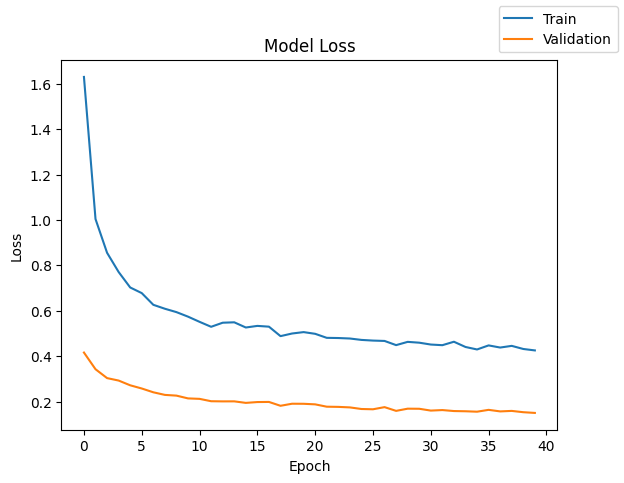

In [ ]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(1618)

#Initializing the neural network
model_4 = Sequential()
model_4.add(Dense(16,activation="relu",input_dim=X_train.shape[1]))
model_4.add(Dropout(0.2))
model_4.add(Dense(8,activation="relu"))
model_4.add(Dense(1,activation="sigmoid"))

print(model_4.summary())

optimizer = tf.keras.optimizers.Adam()    # defining Adam as the optimizer to be used
model_4.compile(loss='binary_crossentropy', optimizer=optimizer, metrics = ['Recall'])

start = time.time()
history = model_4.fit(X_train, y_train, validation_data=(X_val,y_val) , batch_size=batch_size, epochs=epochs, class_weight=cw_dict)
end=time.time()

print("Time taken in seconds ",end-start)

plot(history,'loss')

### Model performance of model_4 on training and validation data

In [ ]:
model_4_train_perf = model_performance_classification(model_4,X_train,y_train)
model_4_train_perf

500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 1000us/step


,Accuracy,Recall,Precision,F1 Score
0,0.977187,0.943935,0.867502,0.901517


In [ ]:
model_4_val_perf = model_performance_classification(model_4,X_val,y_val)
model_4_val_perf

125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


,Accuracy,Recall,Precision,F1 Score
0,0.9805,0.934559,0.891696,0.911842


In [ ]:
y_train_pred_4 = model_4.predict(X_train)
y_val_pred_4 = model_4.predict(X_val)

500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 988us/step
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step  


OBSERVATIONS 1 of 2:

---
- **Evaluation parameters:**
  - **Optimal Recall score**: : ~0.94 and ~0.93 on training and validation set for the model.
  - Accuracy is ~0.98 for both and F1-score is also ~0.91 which indicates optimal prediction.
  - The scores are similar for training and validation.

- **Epoch and Loss function:**
  - Seems like the graph will get flatter so we should look into improving the learning rate.
  - The **model is learning well** as the loss decreases for both training and validation sets over the epochs. There may be scope for improvement here
  - The **model is generalising very well** because the scores in training and validation set are very close and because the training and validation set lines in the graph are decreasing parallely.

### Classification report of model_4 on training and validation data

In [ ]:
print("Classification Report - Train data Model_4", end="\n\n")
cr_train_model_4 = classification_report(y_train,y_train_pred_4 > threshold)
print(cr_train_model_4)

print("Classification Report - Validation data Model_4", end="\n\n")
cr_val_model_4 = classification_report(y_val,y_val_pred_4 > threshold)
print(cr_val_model_4)

Classification Report - Train data Model_4

              precision    recall  f1-score   support

         0.0       0.99      0.98      0.99     15112
         1.0       0.74      0.91      0.82       888

    accuracy                           0.98     16000
   macro avg       0.87      0.94      0.90     16000
weighted avg       0.98      0.98      0.98     16000

Classification Report - Validation data Model_4

              precision    recall  f1-score   support

         0.0       0.99      0.99      0.99      3778
         1.0       0.79      0.88      0.83       222

    accuracy                           0.98      4000
   macro avg       0.89      0.93      0.91      4000
weighted avg       0.98      0.98      0.98      4000



OBSERVATIONS 2 of 2:

- For **Model 4, recall score is good** : 0.91 and 0.88 for training and testing data respectively
- F1-score and precision are both good enough at ( ~ 0.82) and ( ~ 0.7) for predicting errors
- The validation performance is similar than training. Hence the model seems to be generalising well and possibly good enough for unknown test data.

---

- We have a **very good sample model with Adam optimiser**! We can work on imroving the learning of this as we did for SGD previously by tweaking parameters. Let's do that for the next model.

## Model 5

This time we will add more layers and dropout while using a different optimizer.

<table >
<thead>
<th> Hidden Layers</th>
<th> Neurons </th>
<th> Optimiser</th>
<th> Normalization </th>
<th> Regularization/Dropout</th>
<th> Class Weight Distribution</th>
</thead>
<tbody>
<tr>
<td> 3</td>
<td> 32, 16, 8 </td>
<td> Adam</td>
<td> Batch after each HLayer </td>
<td> 1st HLayer:40% dropout </td>
<td> Yes </td>
</tr>
</tbody>
</table>

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │         1,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 8)              │            32 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,209 (8.63 KB)

 Trainable params: 2,097 (8.19 KB)

 Non-trainable params: 112 (448.00 B)

None
Epoch 1/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - Recall: 0.5473 - loss: 1.6787 - val_Recall: 0.4550 - val_loss: 0.4190
Epoch 2/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - Recall: 0.8268 - loss: 1.1264 - val_Recall: 0.7027 - val_loss: 0.3783
Epoch 3/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - Recall: 0.8560 - loss: 0.9478 - val_Recall: 0.8333 - val_loss: 0.3465
Epoch 4/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - Recall: 0.8654 - loss: 0.8215 - val_Recall: 0.8559 - val_loss: 0.3109
Epoch 5/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - Recall: 0.8895 - loss: 0.7254 - val_Recall: 0.8514 - val_loss: 0.2690
Epoch 6/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - Recall: 0.8670 - loss: 0.6561 - val_Recall: 0.8468 - val_loss: 0.2404
Epoch 7/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - Recall: 0.8763 - loss: 0.6159 - val_Recall: 0.8514 - val_loss: 0.2229
Epoch 8/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - Recall: 0.8815 - loss: 0.5773 - val_Recall: 0.8604 - val_loss: 0.2028
Epoch 9/40
40/40 ━

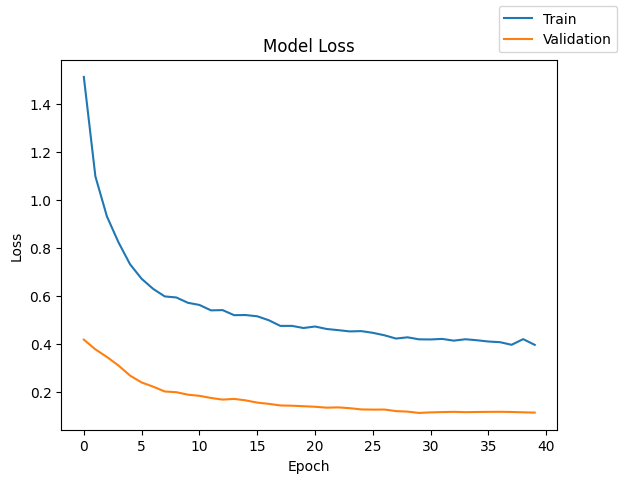

In [ ]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(1618)

#Initializing the neural network

model_5 = Sequential()
model_5.add(Dense(32,activation="relu",input_dim=X_train.shape[1]))
model_5.add(BatchNormalization())
model_5.add(Dropout(0.4))

model_5.add(Dense(16,activation="relu"))
model_5.add(BatchNormalization())

model_5.add(Dense(8, activation = "relu"))
model_5.add(BatchNormalization())

model_5.add(Dense(1,activation="sigmoid"))

print(model_5.summary())

optimizer = tf.keras.optimizers.Adam()
model_5.compile(loss='binary_crossentropy', optimizer=optimizer, metrics = ['Recall'])

start = time.time()
history = model_5.fit(X_train, y_train, validation_data=(X_val,y_val) , batch_size=batch_size, epochs=epochs, class_weight = cw_dict)
end=time.time()

print("Time taken in seconds ",end-start)

plot(history,'loss')

### Model performance of model_5 on training and validation data

In [ ]:
model_5_train_perf = model_performance_classification(model_5,X_train,y_train)
model_5_train_perf

500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step


,Accuracy,Recall,Precision,F1 Score
0,0.986875,0.948534,0.929471,0.938765


In [ ]:
model_5_val_perf = model_performance_classification(model_5,X_val,y_val)
model_5_val_perf

125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


,Accuracy,Recall,Precision,F1 Score
0,0.98525,0.934954,0.925937,0.930392


In [ ]:
y_train_pred_5 = model_5.predict(X_train)
y_val_pred_5 = model_5.predict(X_val)

500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


OBSERVATIONS 1 of 2:

---
- **Evaluation parameters:**
  - **Optimal Recall score**: : ~0.95 and ~0.94 on training and validation set for the model.
  - Accuracy is almost ~0.99 for both, precision is ~0.93 and F1-score is also ~0.93 which near **the best scores yet**!
  - On top of that, the scores are almost similar for training and validation, meaning our model is **generalising very well** to predict for unknown data!!

- **Epoch and Loss function:**
  - The training and validation loss tends to remain the same after 30 epochs
  - The **model is learning well** as the loss decreases for both training and validation sets over the epochs.

### Classification report of model_5 on training and validation data

In [ ]:
print("\n Classification Report - Train data Model_5", end="\n\n")
cr_train_model_5 = classification_report(y_train,y_train_pred_5 > threshold)
print(cr_train_model_5)

print("\n Classification Report - Validation data Model_5", end="\n\n")
cr_val_model_5 = classification_report(y_val,y_val_pred_5 > threshold)
print(cr_val_model_5)


 Classification Report - Train data Model_5

              precision    recall  f1-score   support

         0.0       0.99      0.99      0.99     15112
         1.0       0.86      0.91      0.88       888

    accuracy                           0.99     16000
   macro avg       0.93      0.95      0.94     16000
weighted avg       0.99      0.99      0.99     16000


 Classification Report - Validation data Model_5

              precision    recall  f1-score   support

         0.0       0.99      0.99      0.99      3778
         1.0       0.86      0.88      0.87       222

    accuracy                           0.99      4000
   macro avg       0.93      0.93      0.93      4000
weighted avg       0.99      0.99      0.99      4000



OBSERVATIONS 2 of 2:

---

- For **Model 5**, recall score is similar to the previous Adam optimiser model for predicting errors. It is: 0.91 and 0.88 for training and testing data respectively
- F1-score and precision are very good on both datasets ( ~ 0.88 and ~ 0.86 respectively) for predicting errors. This has improved as compared to previous model
- The validation performance is similar than training. Hence the model seems to be generalising well.


---


- We learnt that by experimenting with a combination of values for adding Dropout, Adam optimiser, a hidden layer, Batch Normalization we have reached a second sample optimal model which can be considering for predicting machine failures.
- Now let's try 1 last method: HE normalisation.

## Model 6

<table >
<thead>
<th> Hidden Layers</th>
<th> Neurons </th>
<th> Optimiser</th>
<th> Normalization </th>
<th> Regularization/Dropout</th>
<th> Class Weight Distribution</th>
</thead>
<tbody>
<tr>
<td> 3</td>
<td> 32, 16, 8  </td>
<td> Adam</td>
<td> HE for each Hlayer</td>
<td> After 1st Hlayer: 0.4</td>
<td> Yes </td>
</tr>
</tbody>
</table>


- Using HE_normal initialiser.
- Expermienting with other parameters

In [ ]:
#threshold = 0.6 #just for testing, not changing

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │         1,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,985 (7.75 KB)

 Trainable params: 1,985 (7.75 KB)

 Non-trainable params: 0 (0.00 B)

None
Epoch 1/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - Recall: 0.6714 - loss: 1.8824 - val_Recall: 0.7973 - val_loss: 0.5196
Epoch 2/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - Recall: 0.7569 - loss: 1.1606 - val_Recall: 0.8333 - val_loss: 0.4393
Epoch 3/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - Recall: 0.8130 - loss: 0.9654 - val_Recall: 0.8649 - val_loss: 0.3524
Epoch 4/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - Recall: 0.8344 - loss: 0.8691 - val_Recall: 0.8739 - val_loss: 0.2855
Epoch 5/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - Recall: 0.8526 - loss: 0.8102 - val_Recall: 0.8694 - val_loss: 0.2677
Epoch 6/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - Recall: 0.8678 - loss: 0.7510 - val_Recall: 0.8739 - val_loss: 0.2492
Epoch 7/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - Recall: 0.8697 - loss: 0.7095 - val_Recall: 0.8784 - val_loss: 0.2434
Epoch 8/40
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - Recall: 0.8444 - loss: 0.6880 - val_Recall: 0.8694 - val_loss: 0.2451
Epoch 9/40
40/40 ━

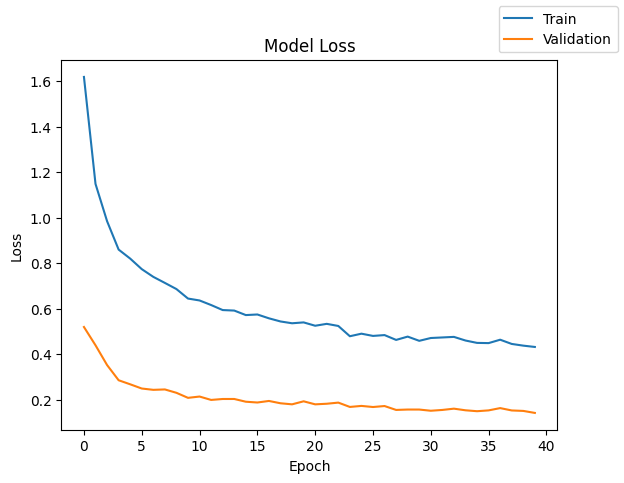

In [ ]:
# clears the current Keras session, resetting all layers and models previously created, freeing up memory and resources.
tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(1618)

model_6 = Sequential()
model_6.add(Dense(32,activation="relu", kernel_initializer="he_normal", input_dim=X_train.shape[1]))
model_6.add(Dropout(0.4))
model_6.add(Dense(16,activation="relu", kernel_initializer="he_normal"))
model_6.add(Dense(8, activation = "relu", kernel_initializer="he_normal"))
model_6.add(Dense(1,activation="sigmoid"))

print(model_6.summary())

optimizer = tf.keras.optimizers.Adam()
model_6.compile(loss='binary_crossentropy', optimizer=optimizer, metrics = ['Recall'])

start = time.time()
history = model_6.fit(X_train, y_train, validation_data=(X_val,y_val) , batch_size=batch_size, epochs=epochs,class_weight=cw_dict)
end=time.time()

print("Time taken in seconds ",end-start)

plot(history,'loss')

### Model performance of model_6 on training and validation data

In [ ]:
model_6_train_perf = model_performance_classification(model_6,X_train,y_train)
model_6_train_perf

500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step


,Accuracy,Recall,Precision,F1 Score
0,0.980187,0.943404,0.885552,0.912136


In [ ]:
model_6_val_perf = model_performance_classification(model_6,X_val,y_val)
model_6_val_perf

125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


,Accuracy,Recall,Precision,F1 Score
0,0.98125,0.934957,0.896538,0.914722


In [ ]:
y_train_pred_6 = model_6.predict(X_train)
y_val_pred_6 = model_6.predict(X_val)

500/500 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step


OBSERVATIONS 1 of 2:

---
- **Evaluation parameters:**
  - **Optimal Recall score**: : ~0.94 and ~0.93 on training and validation set for the model.
  - Accuracy is ~0.98 for both training and validation and F1-score is also ~0.91. These are both excellent scores retaining in validation too.

- **Epoch and Loss function:**
  - The **model is learning well** as the loss decreases for both training and validation sets over the epochs.
  - The **model is generalising very well** because the training and validation set lines in the graph are decreasing parallely.

### Classification report of model_6 on training and validation data

In [ ]:
print("\n Classification Report - Train data Model_3", end="\n\n")
cr_train_model_6 = classification_report(y_train,y_train_pred_6 > threshold)
print(cr_train_model_6)

print("\n Classification Report - Validation data Model_3", end="\n\n")
cr_val_model_6 = classification_report(y_val,y_val_pred_6 > threshold)
print(cr_val_model_6)


 Classification Report - Train data Model_3

              precision    recall  f1-score   support

         0.0       0.99      0.98      0.99     15112
         1.0       0.78      0.90      0.83       888

    accuracy                           0.98     16000
   macro avg       0.89      0.94      0.91     16000
weighted avg       0.98      0.98      0.98     16000


 Classification Report - Validation data Model_3

              precision    recall  f1-score   support

         0.0       0.99      0.99      0.99      3778
         1.0       0.80      0.88      0.84       222

    accuracy                           0.98      4000
   macro avg       0.90      0.93      0.91      4000
weighted avg       0.98      0.98      0.98      4000



OBSERVATIONS 2 of 2:

---

- For **Model 6**, recall score is: 0.89 and 0.88 for training and testing data respectively. The HE normalization scores are comparable to the previous Adam optimiser model with Batch normalization
- F1-score and precision are very good on both datasets ( ~ 0.87 and ~ 0.84 - ~ 0.86 respectively) for predicting errors. These are good scores for considering the model with HE normalisation
- The validation performance is similar than training. Hence the model seems to be generalising well.


---


- We learnt that by experimenting with a combination of values for adding Dropout, Adam optimiser, a hidden layer, HE Normalization we have reached a third sample optimal model which can be considering for predicting machine failures.
- Now let's compare the models

# **Model Performance Comparison and Final Model Selection**

Now, in order to select the final model, we will compare the performances of all the models for the training and validation sets.

In [ ]:
# training performance comparison

models_train_comp_df = pd.concat(
    [model_0_train_perf.T, model_1_train_perf.T, model_2_train_perf.T, model_3_train_perf.T,
     model_4_train_perf.T, model_5_train_perf.T, model_6_train_perf.T],
    axis=1,
)
models_train_comp_df.columns = [
    "Model 0 [SGD Base]",
    "Model 1 [SGD + ClassWgt+Layer]",
    "Model 2 [SGD+m + Dropout + CW+Layer]",
    "Model 3 [SGD+m + BatchN + Dropout + CW+Layer]]",
    "Model 4 [Adam + Dropout +CW]",
    "Model 5 [Adam + BatchN + Dropout +CW+Layer]",
    "Model 6 [Adam + HE_N + Dropout +CW+Layer]"
]
print("Training set performance comparison:")
models_train_comp_df

Training set performance comparison:


,Model 0 [SGD Base],Model 1 [SGD + ClassWgt+Layer],Model 2 [SGD+m + Dropout + CW+Layer],Model 3 [SGD+m + BatchN + Dropout + CW+Layer]],Model 4 [Adam + Dropout +CW],Model 5 [Adam + BatchN + Dropout +CW+Layer],Model 6 [Adam + HE_N + Dropout +CW+Layer]
Accuracy,0.976063,0.968750,0.982313,0.984938,0.977187,0.986875,0.980187
Recall,0.804486,0.941059,0.943999,0.949628,0.943935,0.948534,0.943404
Precision,0.956110,0.826282,0.899078,0.914263,0.867502,0.929471,0.885552
F1 Score,0.863367,0.873487,0.920156,0.931113,0.901517,0.938765,0.912136


In [ ]:
# Validation performance comparison

models_val_comp_df = pd.concat(
    [model_0_val_perf.T, model_1_val_perf.T, model_2_val_perf.T, model_3_val_perf.T,
    model_4_val_perf.T, model_5_val_perf.T, model_6_val_perf.T],
    axis=1,
)
models_val_comp_df.columns = [
    "Model 0 [SGD Base]",
    "Model 1 [SGD + ClassWgt+Layer]",
    "Model 2 [SGD+m + Dropout + CW+Layer]",
    "Model 3 [SGD+m + BatchN + Dropout + CW+Layer]]",
    "Model 4 [Adam + Dropout +CW]",
    "Model 5 [Adam + BatchN + Dropout +CW+Layer]",
    "Model 6 [Adam + HE_N + Dropout +CW+Layer]"
]
print("Validation set performance comparison:")
models_val_comp_df

Validation set performance comparison:


,Model 0 [SGD Base],Model 1 [SGD + ClassWgt+Layer],Model 2 [SGD+m + Dropout + CW+Layer],Model 3 [SGD+m + BatchN + Dropout + CW+Layer]],Model 4 [Adam + Dropout +CW],Model 5 [Adam + BatchN + Dropout +CW+Layer],Model 6 [Adam + HE_N + Dropout +CW+Layer]
Accuracy,0.978000,0.970750,0.982750,0.985000,0.980500,0.985250,0.981250
Recall,0.823001,0.929398,0.939990,0.939062,0.934559,0.934954,0.934957
Precision,0.957392,0.837962,0.904213,0.921252,0.891696,0.925937,0.896538
F1 Score,0.877207,0.877259,0.921228,0.929945,0.911842,0.930392,0.914722


OBSERVATIONS:


---

- Based on comparison of all our models, our first preference is to minimise recall score to minimize replacement costs due to False Negative detections.
- But we should also look at F1 score to minimise other costs too. Later also check Accuracy and precision in terms of priority of scores.
- Also, we should choose a model with better validation thaan training performance if possible since it will be able to generalise well for unknown data.
- So based on these 3 parameters and comparing the models on the 4 scores for training and validationsets from above, we can shortlist:
  - Model 2, Model 4, Model 5 and Model 6 are all similar.
- Finalising **Model 5** as it has the best scores with negligble performance drop in validation. Although it has more computation, it seems to be one of the best performing ones.



Model performance of the **final model** on the **test set**.

In [ ]:
best_model = model_5

In [ ]:
# Test set performance for the best model
best_model_test_perf = model_performance_classification(best_model,X_test,y_test)
best_model_test_perf

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


,Accuracy,Recall,Precision,F1 Score
0,0.9838,0.931401,0.918858,0.925023


In [ ]:
y_test_pred_best = best_model.predict(X_test)

cr_test_best_model = classification_report(y_test, y_test_pred_best> threshold) # Check the classification report of best model on test data.
print(cr_test_best_model)

157/157 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
              precision    recall  f1-score   support

         0.0       0.99      0.99      0.99      4718
         1.0       0.85      0.87      0.86       282

    accuracy                           0.98      5000
   macro avg       0.92      0.93      0.93      5000
weighted avg       0.98      0.98      0.98      5000



OBSERVATIONS:


---
- The performance of final model we selected (Model 5) for predicting the machine's error on recall score on test data is: 0.87
- F1-score is 0.86, which is also optimal for failure predictions to minimise repair and inspection costs


# **Actionable Insights and Recommendations**

**Actionable insights:**

---


**Technical Summary:**
- We started with a dataset with parameters: V1- V40 which do not provide much insight into the type of data.
- The data analysis also showed normal distribution of the data and heat map analysis as well as the boxplots did not give much insights into manual predictions based on the feature importance on the Target variable to predict: failure or no failure in the machinery.
- Hence we made use of Neural Networks to analyse all the data as a whole and ran some methods to come up with a few optimal models.
- After the Standard: Data analysis, Data preprocessing, cleaning up the data( without data leakage), We had 3 sets: train,validation, test. The test set was not used for any models and just used at the end to check the performance of our final model selection.
- We made use of multiple Neural networks models and techniques: SGD, SGD with momentum, Adam optimiser, Batch and He normalization, Regularisation by using Dropout, Adding Hidden layers, tweaking class weights, threshold and other parameters which was a holistic implementation of the techniques learnt.

**Learnings:**

- Use **class weights** for imbalanced classes
- Experimenting with Different optimisers and activation functions depends on your problem and data set. Here we had **0/1 o/p so we used ReLU and Sigmoid** activation functions.
- Changing the threshold can help change the models performance parameters in the classification report. So if we are **not catching enough errors**, we should **reduce the threshold**, and if we need to **reduce the costs** in case we are sending failed machinery when it is not needed, we can **increase the threshold**, to catch less failures.

- Use **Recall Score** to minimise replacement costs. Most of our models mentioned above have been optimised for Recall score > 0.9
- For a **holistic Performance improvement **and to reduce all costs, look at the **F1-Score followed by Accuracy and Precision**. Our models are optimised for those scores too.
- Plot the Loss function vs epoch graph to check the generalisation of the model and **optimise computation costs by using the optimal number of epochs** required. If the last many runs flatten the graph, you can decrease the epoch and reduce computation costs.
- The graph will also help chek the **reduction in loss** over data sets.



---

**Business recommendations:**

---
- "ReneWind" can use our Model 5 or we can provide the couple of back up models based on their costs of computation to predict failures in their machinery.

- The sensors detected for failures and the machines sent for repair or inspection or replacement, should be analyses by the technicians to provide **feedback data**. This will help optimise our models to fine tune threshold and other parameters, to predict better in the future, as well as adjust our computation costs.
- The frequency of data detection by sensors or the number of sensors can be increased if we are not predicting well. By increasing the data set over time, we can optimise our model further.



